# Piecemaker archive: metadata analysis

*Piecemaker* was a web-based application developed by dancer David Kern for The Forsythe Company, used between 2008 and 2014 to document rehearsals and performances. Participants could attach timestamped free-text annotations directly to the concurrent video recording.

This notebook looks at the archive on the metadata level: scope of the documentation, its distribution across productions, authorship, video lengths, and the amount and length of written annotations over time. The csv files with the archive export are not part of this repository. The notebook is committed with its outputs.


In [1]:
import pandas as pd
import numpy as np
from datetime import timedelta
from plotnine import *

events_df = pd.read_csv("pm1-tfc-2016-events.csv")
pieces_df = pd.read_csv("pm1-tfc-2016-pieces.csv")

In [2]:
LANG = 'en'   # 'de' or 'en', switches the figure labels

def L(de, en):
    return de if LANG == 'de' else en

# 'pastel' or 'grey' (greyscale for print)
COLOR_MODE = 'pastel'

if COLOR_MODE == 'grey':
    PASTEL_CYCLE = ['#333333', '#7f7f7f', '#c9c9c9', '#555555', '#a5a5a5', '#e0e0e0']
    FILL_2 = ['#333333', '#c9c9c9']
    FILL_3 = ['#333333', '#7f7f7f', '#c9c9c9']
    RIBBON_WARM = RIBBON_COOL = '#e0e0e0'
else:
    PASTEL_CYCLE = ['#cd867e', '#7ec5cd', '#7ecd86', '#867ecd', '#c5cd7e', '#cd7ec5']
    FILL_2 = ['#cd867e', '#7ec5cd']
    FILL_3 = ['#7ec5cd', '#cd867e', '#7ecd86']
    RIBBON_WARM = '#f0dedb'
    RIBBON_COOL = '#dcebee'

BAR_GREY = '#6b6b6b'
PASTEL_RED, PASTEL_BLUE, PASTEL_GREEN, PASTEL_VIOLET = PASTEL_CYCLE[:4]

theme_set(
    theme_minimal()
    + theme(plot_title=element_text(size=12),
            plot_subtitle=element_text(size=9),
            legend_title=element_blank())
)

In [3]:
# text and name columns are not shown
print(events_df.shape)
events_df.drop(columns=['title', 'description', 'created_by', 'modified_by', 'performers'],
               errors='ignore').head(10)

(9083, 21)


,id,happened_at,dur,event_type,video_id,piece_id,locked,state,updated_at,created_at,highlighted,inherits_title,location,rating,parent_id,account_id
0,5042,2008-01-31 11:33:57.000000,NaN,scene,25685.0,17.0,none,normal,2012-09-10 08:36:19.333824,2008-01-31 11:33:57.000000,False,False,Frankfurt-TAT,0,NaN,1.0
1,5045,2008-01-31 12:28:47.000000,NaN,scene,25686.0,17.0,none,normal,2012-09-10 08:36:19.360620,2008-01-31 12:28:47.000000,False,False,Frankfurt-TAT,0,NaN,1.0
2,5048,2008-01-31 14:20:34.000000,NaN,scene,25686.0,17.0,none,normal,2012-09-10 08:36:19.366552,2008-01-31 14:20:34.000000,False,False,Frankfurt-TAT,0,NaN,1.0
3,5050,2008-01-31 14:57:03.000000,NaN,scene,NaN,17.0,none,normal,2012-08-29 19:56:26.087243,2008-01-31 14:57:03.000000,False,False,Frankfurt-TAT,0,NaN,1.0
4,5053,2008-01-31 14:53:21.000000,NaN,scene,25686.0,17.0,none,normal,2012-09-10 08:36:19.372771,2008-01-31 14:53:21.000000,False,False,Frankfurt-TAT,0,NaN,1.0
5,5054,2008-01-31 16:01:45.000000,NaN,scene,25687.0,17.0,none,normal,2012-09-10 08:36:19.388312,2008-01-31 16:01:45.000000,False,False,Frankfurt-TAT,0,NaN,1.0
6,5058,2008-02-01 11:03:56.000000,NaN,scene,25688.0,17.0,none,normal,2012-09-10 08:36:19.411042,2008-02-01 11:03:56.000000,False,False,Frankfurt-TAT,0,NaN,1.0
7,5059,2008-02-01 11:34:32.000000,NaN,scene,25688.0,17.0,none,normal,2012-09-10 08:36:19.417378,2008-02-01 11:34:32.000000,False,False,Frankfurt-TAT,0,NaN,1.0
8,5062,2008-02-01 12:00:29.000000,NaN,scene,25689.0,17.0,none,normal,2012-09-10 08:36:19.435998,2008-02-01 12:00:29.000000,False,False,Frankfurt-TAT,0,NaN,1.0
9,5067,2008-02-01 12:29:16.000000,NaN,scene,25689.0,17.0,none,normal,2012-09-10 08:36:19.443523,2008-02-01 12:29:16.000000,False,False,Frankfurt-TAT,0,NaN,1.0


In [4]:
events_df['happened_at'] = pd.to_datetime(events_df['happened_at'])

first_event = events_df['happened_at'].min()
last_event = events_df['happened_at'].max()

print("First Event:", first_event)
print("Last Event:", last_event)

First Event: 1987-04-04 11:00:00
Last Event: 2014-05-03 18:10:05.229128


In [5]:
first_event_details = events_df[events_df['happened_at'] == first_event][['happened_at','event_type']]
last_event_details = events_df[events_df['happened_at'] == last_event][['happened_at','event_type']]

In [6]:
first_event_details

,happened_at,event_type
6795,1987-04-04 11:00:00,video


In [7]:
last_event_details

,happened_at,event_type
9076,2014-05-03 18:10:05.229128,video


In [8]:
pieces_df

,id,created_at,title,updated_at,modified_by,short_name,is_active,account_id
0,17,2008-02-07 16:22:57.000000,Yes We Can't,2012-08-29 19:57:41.701255,NaN,YesWeCant,True,1.0
1,33,2008-06-02 10:45:11.000000,Heterotopia,2012-08-29 19:57:41.708069,NaN,Hetero,True,1.0
2,41,2008-08-17 19:54:23.000000,The Defenders,2012-08-29 19:57:41.714740,NaN,DEFENDERS,True,1.0
3,42,2008-09-14 10:58:04.000000,I Don't Believe in Outer Space,2012-08-29 19:57:41.721607,NaN,OUTER,True,1.0
4,43,2009-01-16 19:00:53.000000,Angolo Scuro,2012-08-29 19:57:41.729392,NaN,ANGOLO,True,1.0
5,44,2009-02-27 01:21:15.000000,Nowhere and Everywhere at the Same Time,2012-08-29 19:57:41.735404,NaN,PENDEL,False,1.0
6,45,2009-05-21 14:00:30.000000,The Returns,2012-08-29 19:57:41.741429,NaN,RETURNS,True,1.0
7,51,2009-09-21 16:57:59.000000,Decreation,2012-08-29 19:57:41.747271,NaN,DECREATION,True,1.0
8,52,2009-10-08 12:50:15.000000,Theatrical Arsenal 2*,2012-08-29 19:57:41.753270,NaN,ARSENAL,True,1.0
9,53,2010-02-07 18:49:58.000000,Barishnikov Duo (November Piece),2012-08-29 19:57:41.758815,NaN,novbar,False,1.0


## Overview by piece

Events aggregated by production. The database marks pieces as active or inactive: active pieces are the productions the company worked on during the documentation period, inactive entries are mostly older or peripheral pieces with sparse records, some from early software tests or occasional revival rehearsals.


In [9]:
video_counts = events_df[events_df["event_type"] == "video"] \
    .groupby("piece_id").size().rename("video_count")

# annotations: everything except videos and notes
annotation_mask = ~events_df["event_type"].isin(["video", "note"])
annotation_counts = events_df[annotation_mask] \
    .groupby("piece_id").size().rename("annotation_count")

events_df["date_only"] = pd.to_datetime(events_df["happened_at"]).dt.date
day_counts = events_df.groupby("piece_id")["date_only"].nunique().rename("active_days")

events_df["happened_at"] = pd.to_datetime(events_df["happened_at"], errors="coerce")
first_event = events_df.groupby("piece_id")["happened_at"].min().rename("first_event")
last_event = events_df.groupby("piece_id")["happened_at"].max().rename("last_event")

pieces_info = pieces_df[["id", "title", "is_active"]].set_index("id")

summary_df = (
    pd.concat([video_counts, annotation_counts, day_counts, first_event, last_event], axis=1)
    .join(pieces_info, how="left")
    .reset_index()
    .rename(columns={"index": "piece_id"})
)

summary_df["video_count"] = summary_df["video_count"].fillna(0).astype(int)
summary_df["annotation_count"] = summary_df["annotation_count"].fillna(0).astype(int)
summary_df["active_days"] = summary_df["active_days"].fillna(0).astype(int)

summary_df = summary_df[["piece_id", "title", "is_active", "video_count", "annotation_count", "active_days", "first_event", "last_event"]]

In [10]:
summary_df

,piece_id,title,is_active,video_count,annotation_count,active_days,first_event,last_event
0,17.0,Yes We Can't,True,281,942,99,2008-01-29 11:27:33.000000,2013-01-27 15:08:41.726797
1,33.0,Heterotopia,True,49,14,27,2006-10-24 11:00:00.000000,2013-04-14 08:02:15.662556
2,41.0,The Defenders,True,21,8,7,2007-11-02 12:00:00.000000,2010-10-18 08:38:13.000000
3,42.0,I Don't Believe in Outer Space,True,218,693,85,2008-09-29 08:50:17.000000,2013-07-06 18:36:16.979754
4,43.0,Angolo Scuro,True,101,110,51,2007-03-24 12:00:00.000000,2014-02-02 19:46:16.947766
5,44.0,Nowhere and Everywhere at the Same Time,False,41,125,27,2007-10-23 10:00:00.000000,2010-02-21 07:17:08.000000
6,45.0,The Returns,True,94,196,47,2009-06-08 12:37:01.000000,2014-05-03 18:10:05.229128
7,51.0,Decreation,True,107,1,56,2003-04-04 11:00:00.000000,2012-06-07 10:55:51.000000
8,52.0,Theatrical Arsenal 2*,True,177,812,45,2009-10-22 08:18:36.000000,2011-02-10 19:10:12.000000
9,53.0,Barishnikov Duo (November Piece),False,10,4,4,2010-01-25 12:00:00.000000,2010-02-15 15:00:00.000000


In [11]:
# 'Duo' and 'Nuo' are the same work with two database entries: merged
duo_id = pieces_df.loc[pieces_df["title"] == "Duo", "id"].iloc[0]
nuo_id = pieces_df.loc[pieces_df["title"] == "Nuo", "id"].iloc[0]
merged_events = events_df[events_df["piece_id"].isin([duo_id, nuo_id])]

mask_duo = summary_df["title"] == "Duo"
summary_df.loc[mask_duo, "video_count"]      = int((merged_events["event_type"] == "video").sum())
summary_df.loc[mask_duo, "annotation_count"] = int((~merged_events["event_type"].isin(["video", "note"])).sum())
summary_df.loc[mask_duo, "active_days"]      = int(merged_events["date_only"].nunique())
summary_df.loc[mask_duo, "first_event"]      = merged_events["happened_at"].min()
summary_df.loc[mask_duo, "last_event"]       = merged_events["happened_at"].max()

summary_df.loc[mask_duo, "title"] = "Duo/Nuo"
summary_df = summary_df[summary_df["title"] != "Nuo"]

In [12]:
summary_df

,piece_id,title,is_active,video_count,annotation_count,active_days,first_event,last_event
0,17.0,Yes We Can't,True,281,942,99,2008-01-29 11:27:33.000000,2013-01-27 15:08:41.726797
1,33.0,Heterotopia,True,49,14,27,2006-10-24 11:00:00.000000,2013-04-14 08:02:15.662556
2,41.0,The Defenders,True,21,8,7,2007-11-02 12:00:00.000000,2010-10-18 08:38:13.000000
3,42.0,I Don't Believe in Outer Space,True,218,693,85,2008-09-29 08:50:17.000000,2013-07-06 18:36:16.979754
4,43.0,Angolo Scuro,True,101,110,51,2007-03-24 12:00:00.000000,2014-02-02 19:46:16.947766
5,44.0,Nowhere and Everywhere at the Same Time,False,41,125,27,2007-10-23 10:00:00.000000,2010-02-21 07:17:08.000000
6,45.0,The Returns,True,94,196,47,2009-06-08 12:37:01.000000,2014-05-03 18:10:05.229128
7,51.0,Decreation,True,107,1,56,2003-04-04 11:00:00.000000,2012-06-07 10:55:51.000000
8,52.0,Theatrical Arsenal 2*,True,177,812,45,2009-10-22 08:18:36.000000,2011-02-10 19:10:12.000000
9,53.0,Barishnikov Duo (November Piece),False,10,4,4,2010-01-25 12:00:00.000000,2010-02-15 15:00:00.000000


In [13]:
totals_all = {
    "total_videos": summary_df["video_count"].sum(),
    "total_annotations": summary_df["annotation_count"].sum(),
    "total_active_days": summary_df["active_days"].sum()
}

totals_df = pd.DataFrame.from_dict(totals_all, orient='index', columns=["value"])
totals_df.index = ["video count", "annotation count", "recording days"]
totals_df.reset_index(inplace=True)
totals_df.columns = ["metric", "value"]

totals_df.reset_index(drop=True)

,metric,value
0,video count,2386
1,annotation count,6516
2,recording days,983


In [14]:
active_summary = summary_df[summary_df["is_active"] == True]

totals_active = {
    "total_videos": active_summary["video_count"].sum(),
    "total_annotations": active_summary["annotation_count"].sum(),
    "total_active_days": active_summary["active_days"].sum()
}

print("Sum for all pieces marked as 'active' in the database:")
for key, value in totals_active.items():
    print(f"{key}: {value}")

Sum for all pieces marked as 'active' in the database:
total_videos: 1923
total_annotations: 6348
total_active_days: 713


## Active pieces: documentation volume

Videos, annotations and recording days for the active pieces, sorted chronologically by first record. The distribution is uneven: some productions have dense written records, others consist mainly of video entries.


In [15]:
active_df = summary_df[summary_df["is_active"] == True].copy()

active_df = active_df[["title", "video_count", "annotation_count", "active_days", "first_event"]]
active_df.columns = ["title", "video count", "annotation count", "recording days", "first record"]

active_df = active_df.sort_values(by="first record")

In [16]:
active_df.reset_index(drop=True)

,title,video count,annotation count,recording days,first record
0,Decreation,107,1,56,2003-04-04 11:00:00.000000
1,Heterotopia,49,14,27,2006-10-24 11:00:00.000000
2,Angolo Scuro,101,110,51,2007-03-24 12:00:00.000000
3,The Defenders,21,8,7,2007-11-02 12:00:00.000000
4,Yes We Can't,281,942,99,2008-01-29 11:27:33.000000
5,I Don't Believe in Outer Space,218,693,85,2008-09-29 08:50:17.000000
6,The Returns,94,196,47,2009-06-08 12:37:01.000000
7,Theatrical Arsenal 2*,177,812,45,2009-10-22 08:18:36.000000
8,Whole in the Head,198,715,58,2010-10-18 10:11:10.000000
9,Sider,234,900,86,2011-04-13 10:27:01.000000


In [17]:
# active pieces with >= 150 annotations; days = calendar days with at least one entry of any type
MIN_ANNOTATIONS = 150

active_pieces = (
    summary_df[summary_df["is_active"] == True]
    .query("annotation_count >= @MIN_ANNOTATIONS")
    .sort_values("first_event")
    .copy()
)
active_pieces["from"] = pd.to_datetime(active_pieces["first_event"]).dt.year

# video hours, plausible durations only (0 < dur <= 12 h)
videos = events_df[events_df["event_type"] == "video"].copy()
videos["dur"] = pd.to_numeric(videos["dur"], errors="coerce")
videos = videos[(videos["dur"] > 0) & (videos["dur"] <= 12 * 3600)]
video_hours = videos.groupby("piece_id")["dur"].sum() / 3600
active_pieces["video_hours"] = active_pieces["piece_id"].map(video_hours).round(0).astype(int)

overview = active_pieces[["title", "video_count", "video_hours",
                          "annotation_count", "active_days", "from"]]
overview = overview.rename(columns={"title": "piece", "video_count": "videos",
                                    "annotation_count": "annotations", "active_days": "days"})
overview.reset_index(drop=True)

,piece,videos,video_hours,annotations,days,from
0,Yes We Can't,281,286,942,99,2008
1,I Don't Believe in Outer Space,218,189,693,85,2008
2,The Returns,94,116,196,47,2009
3,Theatrical Arsenal 2*,177,139,812,45,2009
4,Whole in the Head,198,120,715,58,2010
5,Sider,234,230,900,86,2011
6,Now This When Not That,78,66,517,19,2011
7,STELLENTSTELLEN,103,100,563,41,2011
8,Hellerau,78,93,699,33,2013


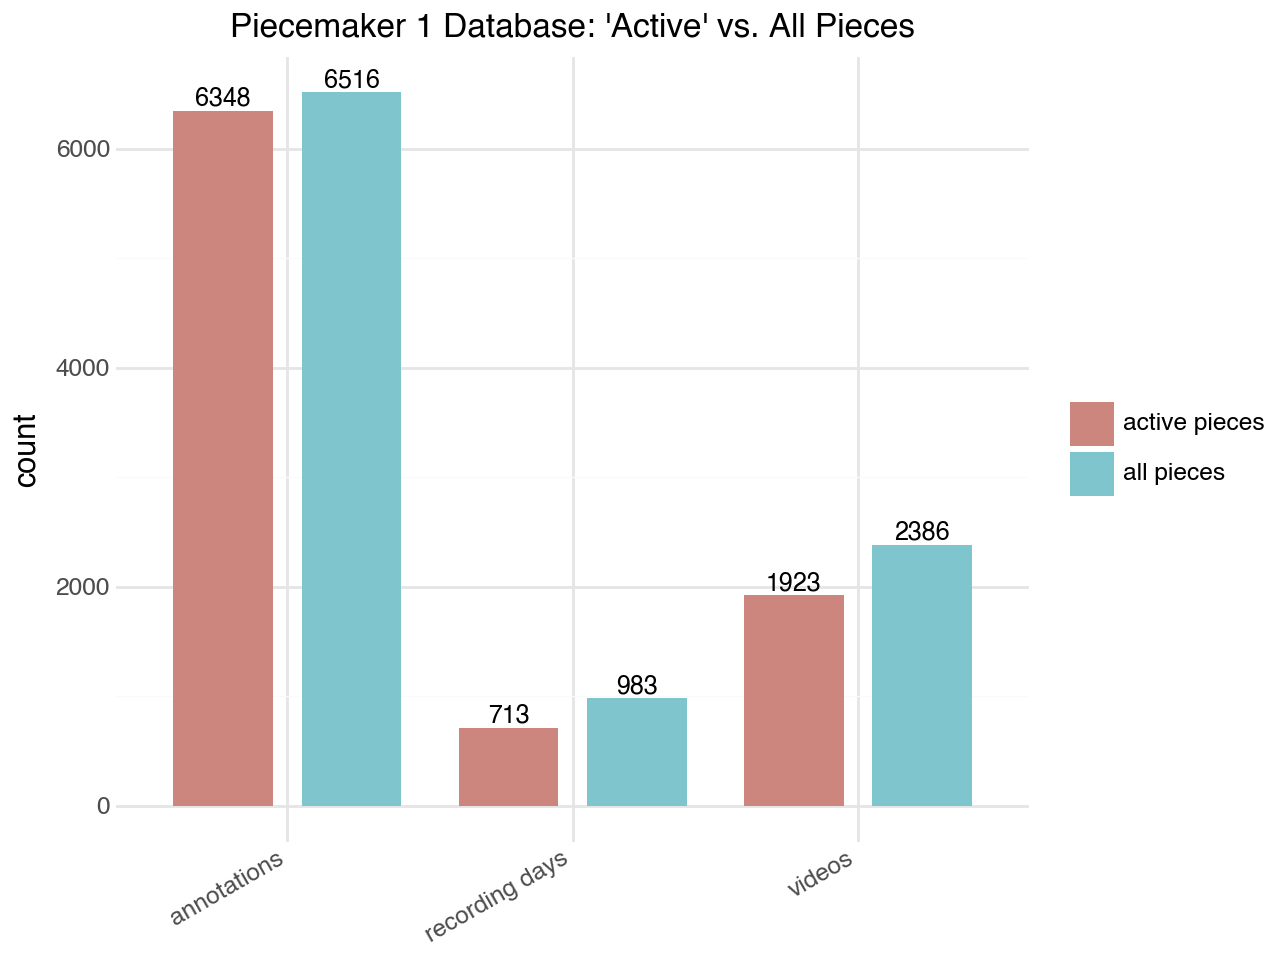

In [18]:
plot_data = pd.DataFrame({
    "category": ["videos", "annotations", "recording days"],
    "all pieces": [totals_all["total_videos"], totals_all["total_annotations"], totals_all["total_active_days"]],
    "active pieces": [totals_active["total_videos"], totals_active["total_annotations"], totals_active["total_active_days"]]
})

plot_data_long = plot_data.melt(id_vars="category", var_name="type", value_name="count")

if LANG == 'de':
    plot_data_long = plot_data_long.assign(
        category=plot_data_long['category'].map({'videos': 'Videos', 'annotations': 'Annotationen',
                                                 'recording days': 'Aufnahmetage'}),
        type=plot_data_long['type'].map({'all pieces': 'alle Stücke', 'active pieces': 'aktive Stücke'}),
    )

dodge = position_dodge(width=0.9)

gg = (
    ggplot(plot_data_long, aes(x='category', y='count', fill='type'))
    + geom_bar(stat='identity', position=dodge, width=0.7)
    + geom_text(aes(label='count'), position=dodge, va='bottom', size=9, format_string='{:.0f}')
    + scale_fill_manual(values=FILL_2)
    + labs(title=L("Piecemaker-1-Datenbank: 'aktive' vs. alle Stücke",
                   "Piecemaker 1 Database: 'Active' vs. All Pieces"),
           y=L('Anzahl', 'count'), x="")
    + theme(axis_text_x=element_text(rotation=30, hjust=1))
)

gg

In [19]:
active_df = summary_df[summary_df["is_active"] == True]
active_df

,piece_id,title,is_active,video_count,annotation_count,active_days,first_event,last_event
0,17.0,Yes We Can't,True,281,942,99,2008-01-29 11:27:33.000000,2013-01-27 15:08:41.726797
1,33.0,Heterotopia,True,49,14,27,2006-10-24 11:00:00.000000,2013-04-14 08:02:15.662556
2,41.0,The Defenders,True,21,8,7,2007-11-02 12:00:00.000000,2010-10-18 08:38:13.000000
3,42.0,I Don't Believe in Outer Space,True,218,693,85,2008-09-29 08:50:17.000000,2013-07-06 18:36:16.979754
4,43.0,Angolo Scuro,True,101,110,51,2007-03-24 12:00:00.000000,2014-02-02 19:46:16.947766
6,45.0,The Returns,True,94,196,47,2009-06-08 12:37:01.000000,2014-05-03 18:10:05.229128
7,51.0,Decreation,True,107,1,56,2003-04-04 11:00:00.000000,2012-06-07 10:55:51.000000
8,52.0,Theatrical Arsenal 2*,True,177,812,45,2009-10-22 08:18:36.000000,2011-02-10 19:10:12.000000
18,104.0,Whole in the Head,True,198,715,58,2010-10-18 10:11:10.000000,2012-09-22 18:07:08.452270
21,108.0,Sider,True,234,900,86,2011-04-13 10:27:01.000000,2014-02-27 19:48:16.512743


In [20]:
active_df = summary_df[summary_df["is_active"] == True]

plot_df = active_df[["title", "video_count", "annotation_count", "active_days", "first_event"]].melt(
    id_vars= ["title", "first_event"],
    var_name="type",
    value_name="count"
)

plot_df["type"] = plot_df["type"].replace({
    "video_count": "sum videos",
    "annotation_count": "sum annotations",
    "active_days": "sum recording days",
})

# chronological order
title_order = (
    plot_df.groupby("title")["first_event"]
    .first()
    .sort_values()
    .index
)

plot_df["title"] = pd.Categorical(plot_df["title"], categories=title_order, ordered=True)

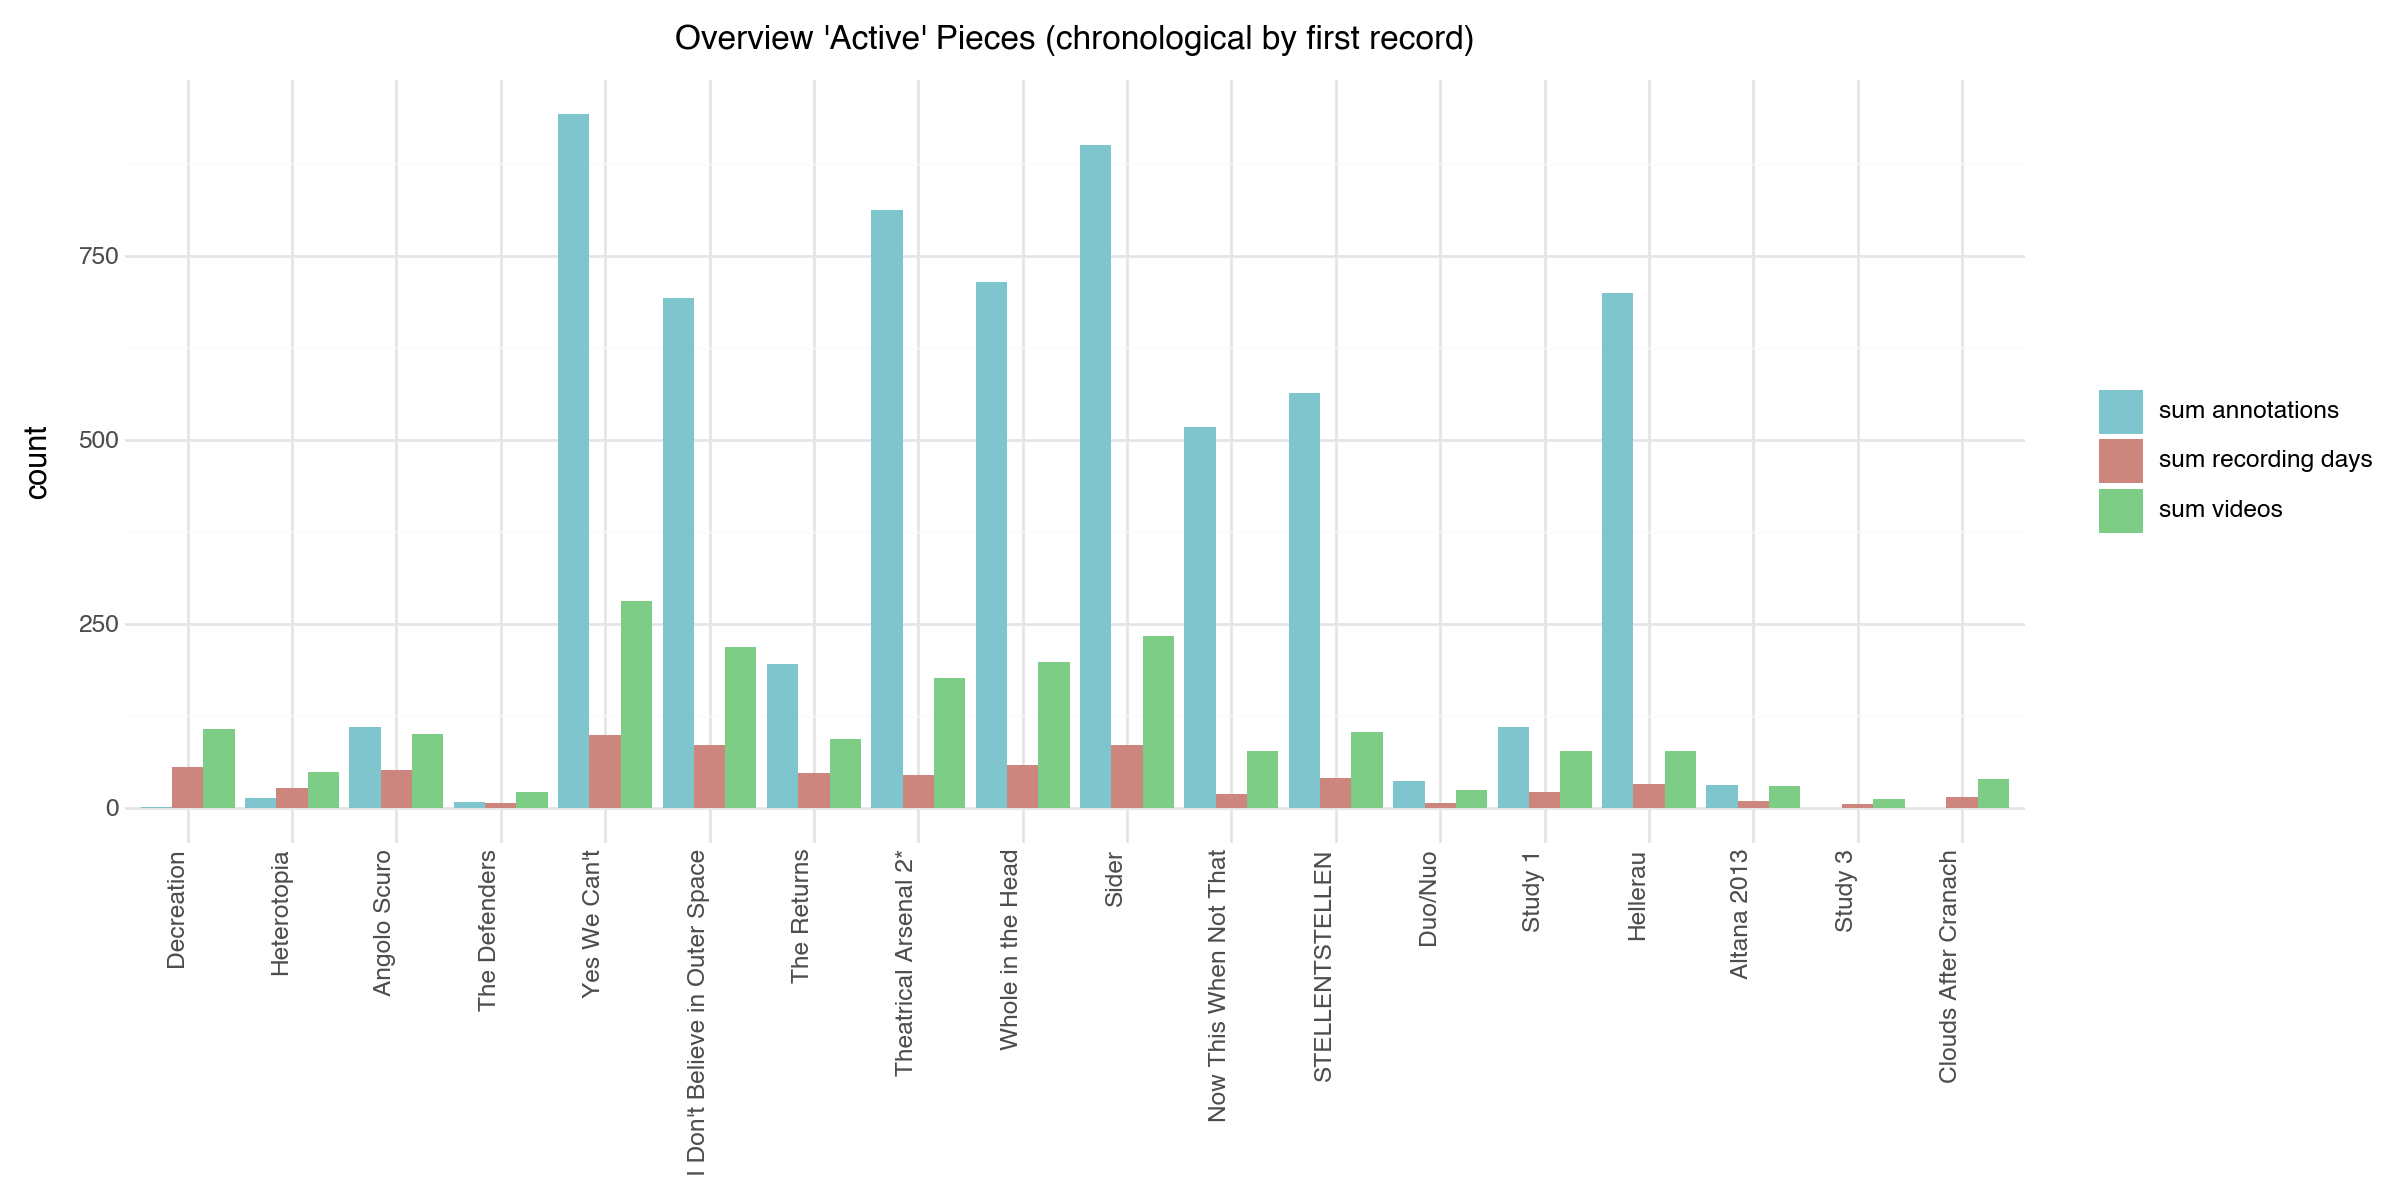

In [21]:
if LANG == 'de':
    pdf = plot_df.assign(type=plot_df['type'].map({'sum videos': 'Videos',
                                                   'sum annotations': 'Annotationen',
                                                   'sum recording days': 'Aufnahmetage'}))
else:
    pdf = plot_df

gg = (
    ggplot(pdf, aes(x='title', y='count', fill='type'))
    + geom_bar(stat='identity', position='dodge')
    + scale_fill_manual(values=FILL_3)
    + labs(title=L("Überblick 'aktive' Stücke (chronologisch nach erstem Eintrag)",
                   "Overview 'Active' Pieces (chronological by first record)"),
           x="", y=L('Anzahl', 'count'))
    + theme(axis_text_x=element_text(rotation=90, hjust=1), figure_size=(12, 6))
)

gg

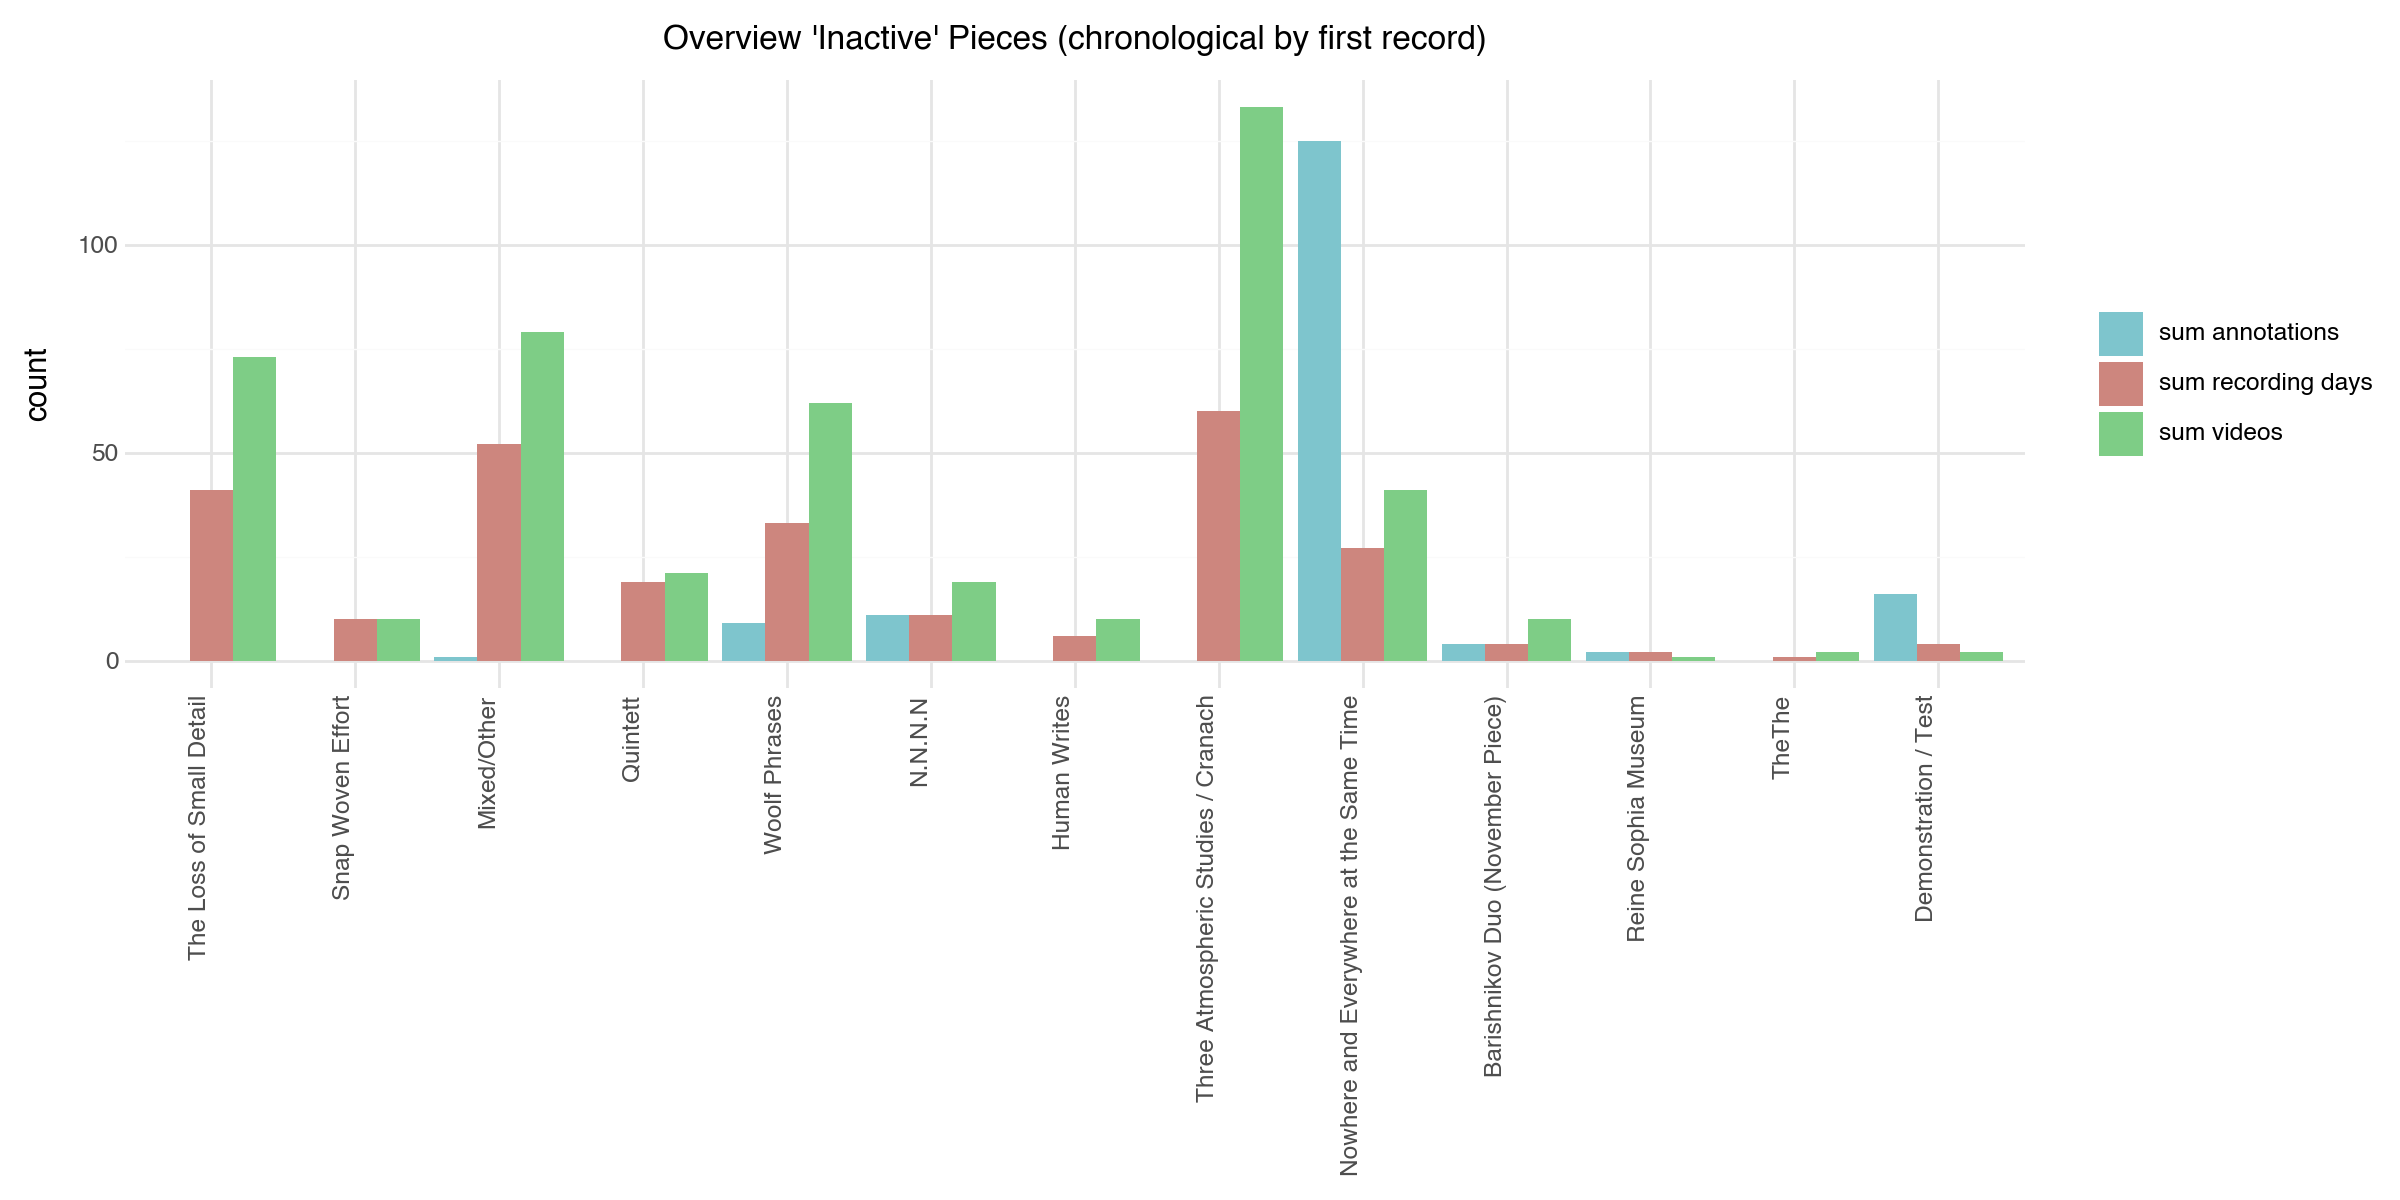

In [22]:
inactive_df = summary_df[summary_df["is_active"] == False].copy()
inactive_long = inactive_df[["title", "video_count", "annotation_count", "active_days", "first_event"]].melt(
    id_vars=["title", "first_event"], var_name="type", value_name="count")
inactive_long["type"] = inactive_long["type"].replace({
    "video_count": "sum videos", "annotation_count": "sum annotations",
    "active_days": "sum recording days"})

# order the pieces chronologically by their first entry
chrono_order = inactive_long.groupby("title")["first_event"].first().sort_values().index
inactive_long["title"] = pd.Categorical(inactive_long["title"], categories=chrono_order, ordered=True)

if LANG == 'de':
    inactive_long["type"] = inactive_long["type"].map({'sum videos': 'Videos',
        'sum annotations': 'Annotationen', 'sum recording days': 'Aufnahmetage'})

(ggplot(inactive_long, aes(x='title', y='count', fill='type'))
 + geom_bar(stat='identity', position='dodge')
 + scale_fill_manual(values=FILL_3)
 + labs(title=L("Überblick 'inaktive' Stücke (chronologisch nach erstem Eintrag)",
                "Overview 'Inactive' Pieces (chronological by first record)"),
        x="", y=L('Anzahl', 'count'))
 + theme(axis_text_x=element_text(rotation=90, hjust=1), figure_size=(12, 6))
)

## Annotation activity over time

When was documented, per production? Each band is normalised to its own maximum, so its thickness shows the distribution within a piece and is not comparable across pieces.

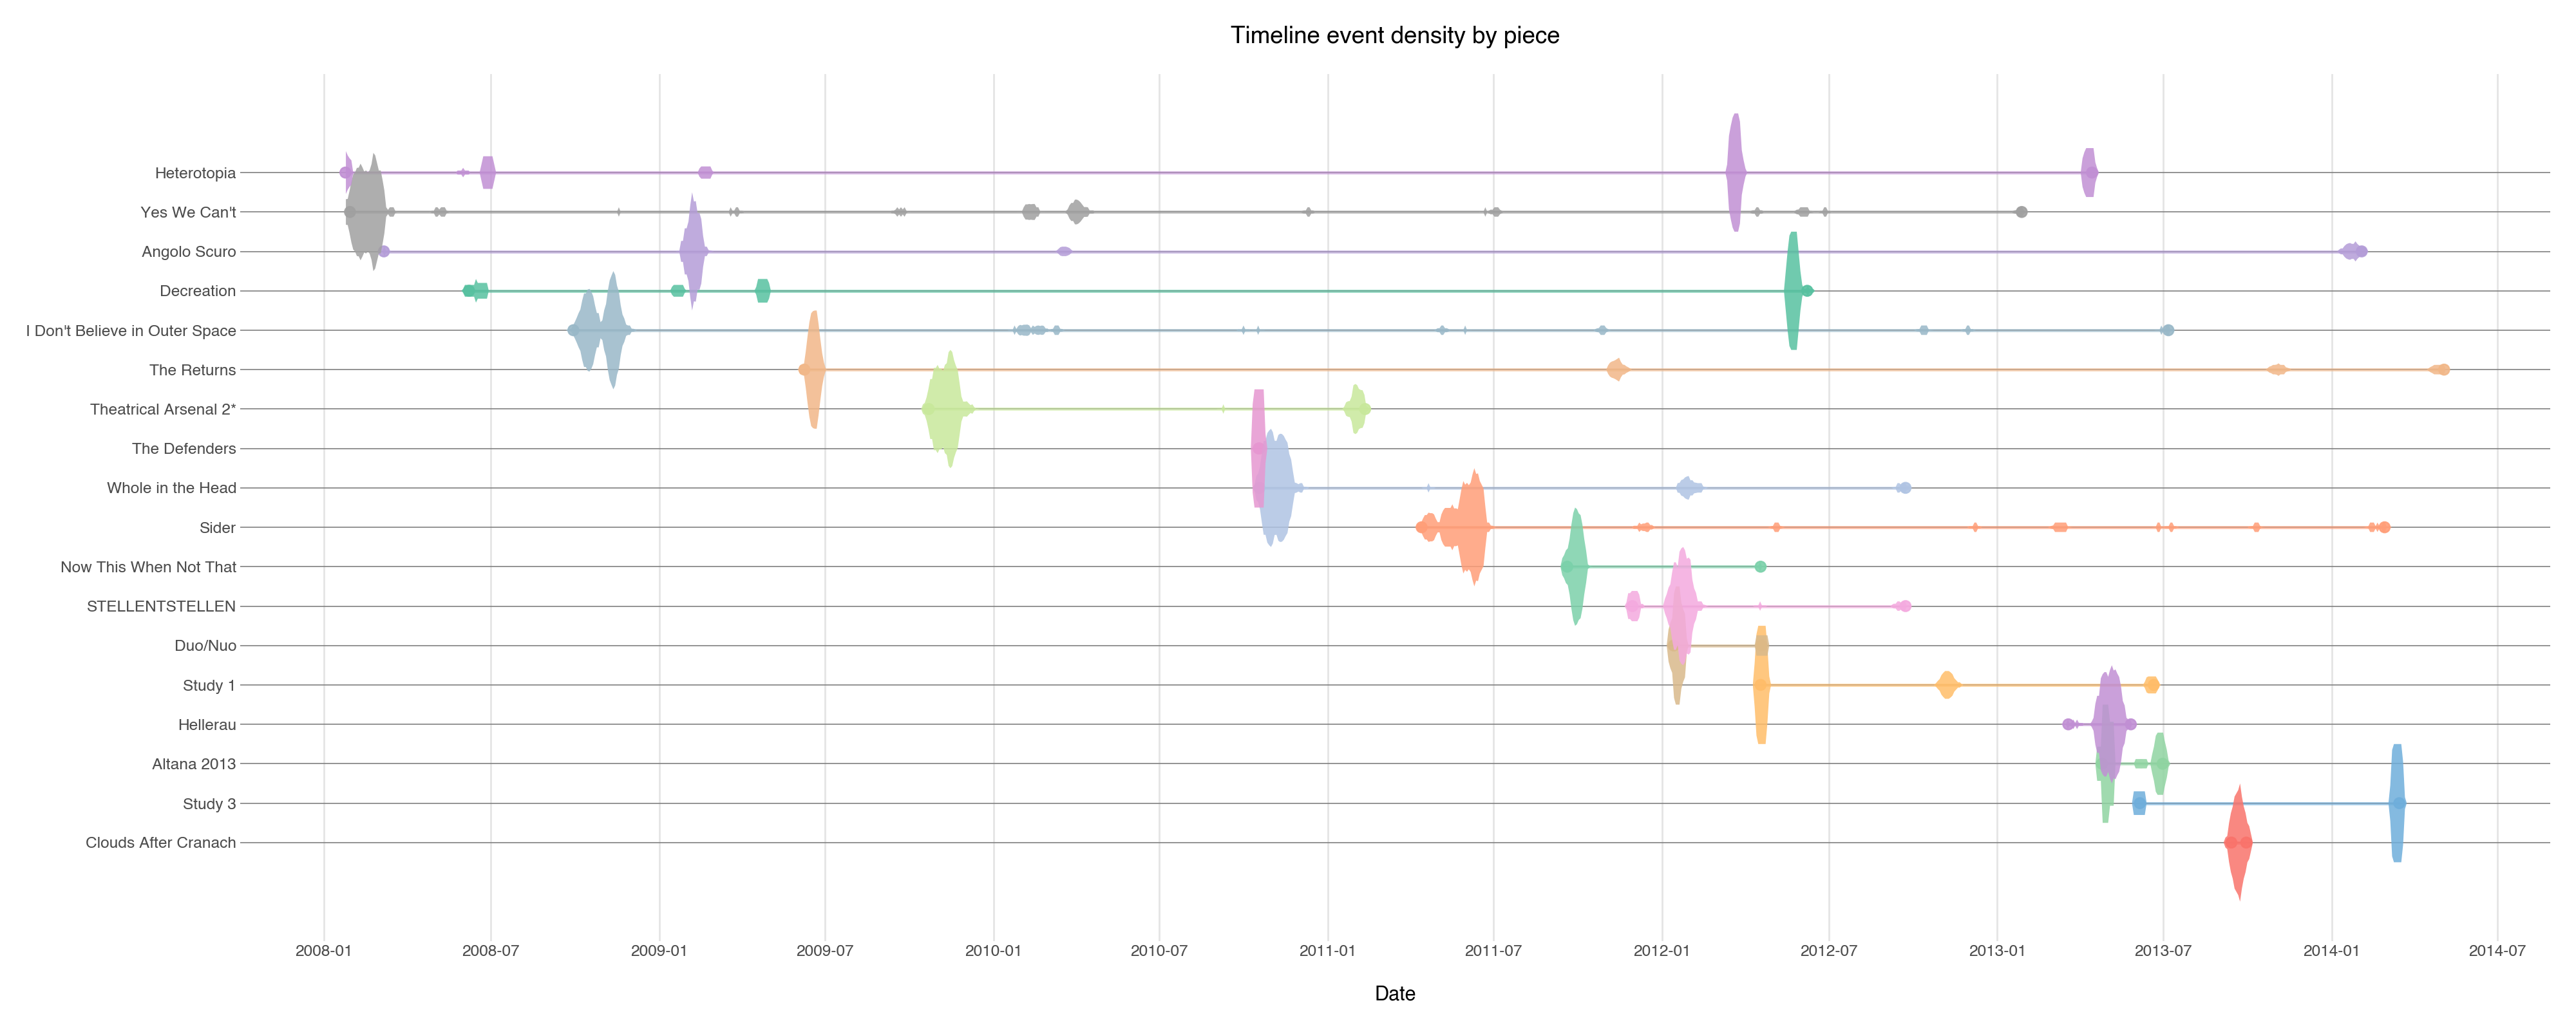

In [23]:
FREQ = "2D"         # bin width
SMOOTH_WIN = 7      # rolling mean window (bins) for smoothing
MAX_WIDTH = 1.5      # max half-thickness of a violin (y units)
MIN_WIDTH = 0.12     # minimal visible thickness for non-zero bins

# active pieces, Duo/Nuo merged
df = (
    events_df
    .merge(pieces_df[['id', 'title', 'is_active']].rename(columns={'title': 'piece_title'}), left_on='piece_id', right_on='id', how='left')
    .assign(title_merged=lambda d: np.where(d['piece_title'].isin(['Duo', 'Nuo']), 'Duo/Nuo', d['piece_title']))
)

start_date = pd.Timestamp("2008-01-01")  # earlier entries are back-dated archive videos
df = df[(df['is_active'] == True) & (df['happened_at'] >= start_date)].copy()

df = df[['happened_at', 'title_merged']].rename(columns={'title_merged': 'piece'})

# one row per piece
piece_order = (
    df.groupby('piece')['happened_at']
      .min()
      .sort_values(ascending=False)
      .index.tolist()
)
y_centers = {piece: i for i, piece in enumerate(piece_order, start=1)}

# common time grid
tmin = df['happened_at'].min()
tmax = df['happened_at'].max()
bin_edges = pd.date_range(tmin.floor('D'), tmax.ceil('D') + pd.Timedelta(FREQ), freq=FREQ)
bin_centers = bin_edges[:-1] + (bin_edges[1:] - bin_edges[:-1]) / 2

# one band per piece: counts per bin (empty bins included), smoothed, normalised to the piece's maximum
polys = []

for piece in piece_order:
    d_piece = df[df['piece'] == piece]
    if d_piece.empty:
        continue

    s = pd.Series(1, index=d_piece['happened_at']).sort_index()

    full_idx = pd.date_range(bin_edges[0], bin_edges[-1] - pd.Timedelta(seconds=1), freq='D')
    s_full = pd.Series(0, index=full_idx).add(s, fill_value=0)

    counts = (
        s_full
        .resample(FREQ, label='left', closed='left')
        .sum()
        .reindex(bin_edges[:-1], fill_value=0)
    )

    counts_smooth = counts.rolling(window=SMOOTH_WIN, min_periods=1, center=True).mean()

    max_c = counts_smooth.max()
    if max_c <= 0:
        continue

    widths = (counts_smooth / max_c) * MAX_WIDTH
    widths = np.where(counts > 0, np.maximum(widths, MIN_WIDTH), widths)

    y0 = y_centers[piece]
    xs = bin_centers

    y_upper = y0 + widths
    y_lower = y0 - widths

    poly_upper = pd.DataFrame({
        'x': xs,
        'y': y_upper,
        'piece': piece
    })

    poly_lower = pd.DataFrame({
        'x': xs[::-1],
        'y': y_lower[::-1],
        'piece': piece
    })

    poly = pd.concat([poly_upper, poly_lower], ignore_index=True)
    polys.append(poly)

poly_df = pd.concat(polys, ignore_index=True)

extent_df = (
    df.groupby('piece', as_index=False)['happened_at']
      .agg(first='min', last='max')
      .assign(y=lambda d: d['piece'].map(y_centers))
)

custom_colors_list = [
    "#f9736b", "#6faedb", "#8fd4a1", "#c18fd4", "#ffbd69",
    "#d9b98b", "#f4aadf", "#7bd1aa", "#ff9e78", "#b0c4e3",
    "#e697d1", "#c8e89b", "#f1b788", "#99b8c8", "#57c1a0",
    "#b49dd8", "#a0a0a0", "#c18fd4"
]
if COLOR_MODE == 'grey':
    # grey version for print
    custom_colors_list = ['#4d4d4d', '#969696', '#c9c9c9'] * 6
pieces = list(y_centers.keys())

custom_colors = {piece: custom_colors_list[i % len(custom_colors_list)] for i, piece in enumerate(pieces)}

p = (
    ggplot(poly_df, aes(x='x', y='y', fill='piece', group='piece'))
    + geom_segment(
        data=extent_df,
        mapping=aes(x='first', xend='last', y='y', yend='y', color='piece'),
        inherit_aes=False,
        size=1.0, alpha=0.6
    )
    + geom_point(
        data=extent_df,
        mapping=aes(x='first', y='y', color='piece'),
        inherit_aes=False,
        size=2.8, alpha=0.9
    )
    + geom_point(
        data=extent_df,
        mapping=aes(x='last', y='y', color='piece'),
        inherit_aes=False,
        size=2.8, alpha=0.9
    )
    + geom_polygon(alpha=0.85, color=None,)
    + theme_minimal()
    + theme(
        legend_position='none',
        panel_grid_major_y=element_line(color='gray', size=0.6),
        panel_grid_minor_y=element_blank(),
        panel_grid_minor=element_blank(),
        figure_size=(20, 8)
    )
    + scale_x_datetime(date_breaks='6 months', date_labels='%Y-%m')
    + scale_y_continuous(
        breaks=list(y_centers.values()),
        labels=list(y_centers.keys())
    )
    + scale_fill_manual(values=custom_colors)
    + scale_color_manual(values=custom_colors)
    + labs(
        title=L('Zeitliche Dichte der Einträge je Produktion', 'Timeline event density by piece'),
        x=L('Datum', 'Date'),
        y=''
    )
)
p

## Authorship

Piecemaker was designed as a collaborative tool, but usage was heavily concentrated: of the entries with a recorded author, about 64% (including video entries) and about 72% of the text annotations come from a single contributor, the company's dramaturge. The developer and production assistants account for most of the rest. For 45% of all entries and a third of the text annotations the export has no author. Author names are shortened to initials for display. The chart uses a square-root scale, otherwise the smaller contributors would be invisible.

In [24]:
def clean_author(series):
    return (
        series
        .str.lower()
        .str.extract(r"^([a-z]+)")
        .iloc[:, 0]
        .str.capitalize()
    )

events_df["created_by_clean"] = clean_author(events_df["created_by"])

# shorten the first names to initials (for online repo) add a second letter where one letter would be ambiguous
short_labels = {}
used = set()
for name in events_df["created_by_clean"].value_counts().index:
    label = name[0] + "."
    k = 2
    while label in used:
        label = name[:k] + "."
        k += 1
    used.add(label)
    short_labels[name] = label
events_df["author_short"] = events_df["created_by_clean"].map(short_labels)

# basis of the chart: all entries with an author, incl. videos
counts = events_df["author_short"].value_counts().reset_index()
counts.columns = ["name", "number of entries"]
total_entries = counts["number of entries"].sum()
counts["percentage"] = (counts["number of entries"] / total_entries * 100).round(2).astype(str) + "%"
counts = counts[["name", "number of entries", "percentage"]]

# Text annotations only (excl. video and note entries)
annotation_events = events_df[~events_df["event_type"].isin(["video", "note"])]
counts_ann = clean_author(annotation_events["created_by"]).map(short_labels).value_counts(normalize=True).mul(100).round(1)

print("Share of all entries with a recorded author (incl. videos), top 5:")
print(events_df["author_short"].value_counts(normalize=True).mul(100).round(1).head(5).to_string())
print("\nShare of text annotations with a recorded author, top 5:")
print(counts_ann.head(5).to_string())

missing_all = events_df["created_by"].isna()
missing_ann = annotation_events["created_by"].isna()
print(f"\nNo author in export: {missing_all.sum()} of {len(events_df)} entries ({missing_all.mean():.0%}), "
      f"{missing_ann.sum()} of {len(annotation_events)} text annotations ({missing_ann.mean():.0%})")
print("Missing by entry type:", events_df.groupby("event_type")["created_by"].apply(lambda x: x.isna().sum())
      .loc[lambda x: x > 0].to_dict())
top = counts_ann.index[0]
share_top = (clean_author(annotation_events["created_by"]).map(short_labels) == top).mean()
print(f"Share of {top} in all text annotations, incl. those without author: {share_top:.0%}")

Share of all entries with a recorded author (incl. videos), top 5:
author_short
F.     64.0
D.      9.2
M.      5.8
T.      5.1
Ma.     4.0

Share of text annotations with a recorded author, top 5:
0
F.     71.9
D.      6.0
T.      5.1
Ma.     4.6
S.      4.0

No author in export: 4085 of 9083 entries (45%), 2142 of 6516 text annotations (33%)
Missing by entry type: {'discussion': 3, 'headline': 1, 'scene': 2138, 'video': 1943}
Share of F. in all text annotations, incl. those without author: 48%


In [25]:
counts

,name,number of entries,percentage
0,F.,3201,64.05%
1,D.,459,9.18%
2,M.,288,5.76%
3,T.,257,5.14%
4,Ma.,201,4.02%
5,S.,176,3.52%
6,B.,98,1.96%
7,E.,85,1.7%
8,P.,84,1.68%
9,Fi.,68,1.36%


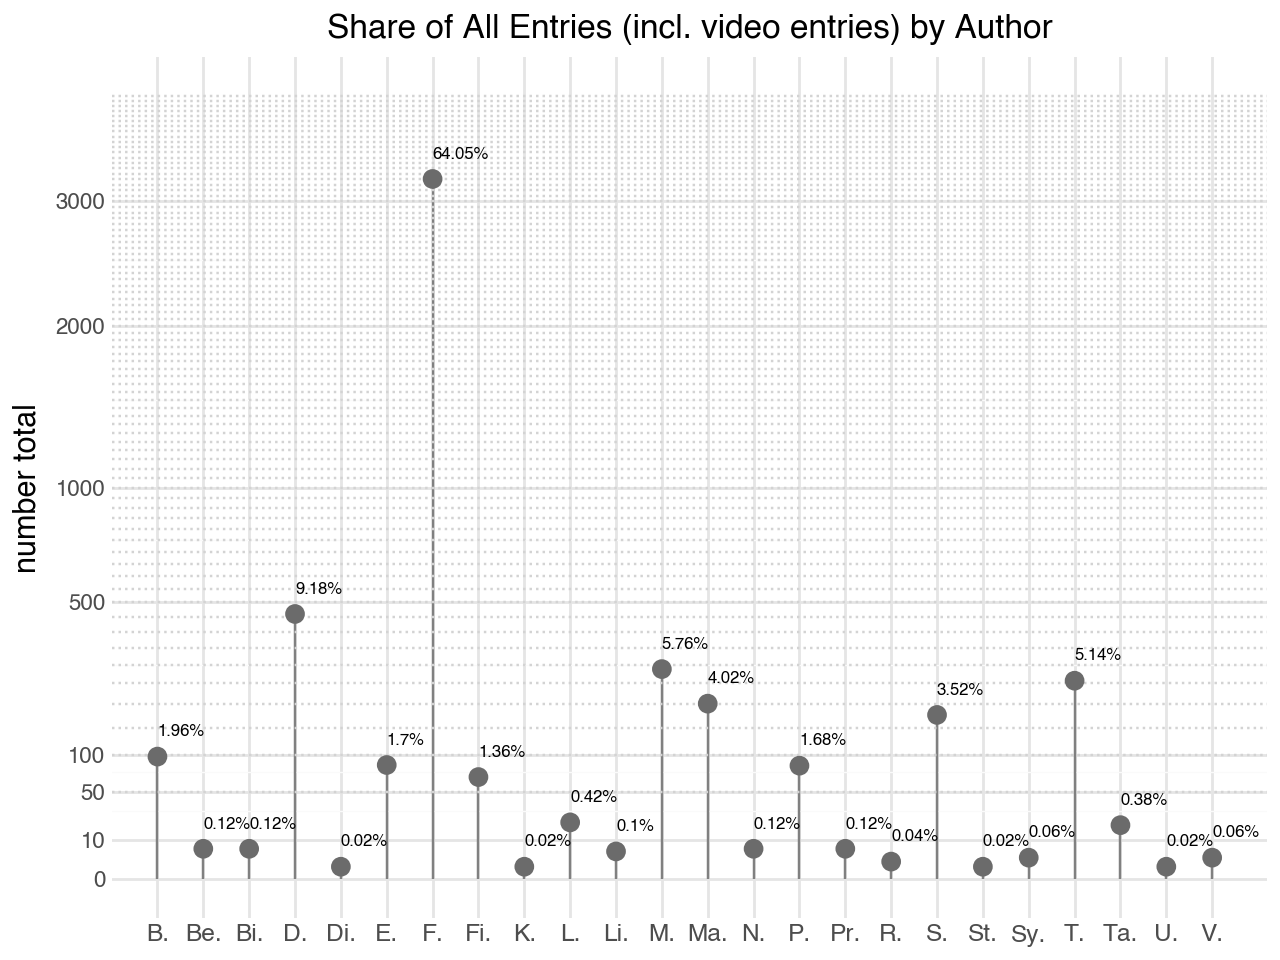

In [26]:
max_value = counts["number of entries"].max()
number_names = len(counts["name"])
breaks = np.arange(50, max_value + 800, 50)

gg = (
    ggplot(counts, aes(x='number of entries', y='name'))
    + geom_segment(aes(x=0, xend='number of entries', y='name', yend='name'), color='gray')
    + geom_vline(xintercept=breaks, color="lightgray", linetype='dotted')
    + geom_point(size=3, color=BAR_GREY)
    + geom_text(aes(label='percentage'), ha='left', nudge_x=2, size=6)
    # sqrt scale to account for huge differences between authors
    + scale_x_continuous(
        trans='sqrt',
        breaks=[0, 10, 50, 100, 500, 1000, 2000, 3000],
    )
    + expand_limits(y=[0, number_names * 1.05])
    + coord_flip()
    + labs(
        title=L('Anteil aller Einträge (einschließlich Videoeinträge) je Autor:in',
                'Share of All Entries (incl. video entries) by Author'),
        x=L('Anzahl gesamt', 'number total'), y=""
    )
    + theme(
        axis_text_y=element_text(size=8),
        legend_position='none'
    )
    + expand_limits(x=[0, max_value * 1.1])
)
gg

## Recording locations

Most recordings took place in the company's studio; performances at external venues form a smaller subset.


In [27]:
location_counts = events_df['location'].dropna().value_counts().reset_index()
location_counts.columns = ['location', 'count']

total = location_counts['count'].sum()
location_counts['percentage'] = (location_counts['count'] / total * 100).round(1).astype(str) + '%'

location_counts

,location,count,percentage
0,Frankfurt-Schmidtstrasse,1347,42.5%
1,Frankfurt-TAT,787,24.8%
2,Hellerau,785,24.8%
3,Frankfurt-Offenbacher Landstrasse,145,4.6%
4,Frankfurt-Opera House,87,2.7%
5,none,18,0.6%


## Video duration

Recording lengths are strongly right-skewed (many short recordings, a few very long ones), so median and interquartile range are reported instead of mean and standard deviation. There is no clear trend over time: recording length depended on the session, not on a changing convention.


In [28]:
video_df = events_df[events_df['event_type'] == 'video'][['happened_at', 'dur']].copy()
video_df['happened_at'] = pd.to_datetime(video_df['happened_at'])
video_df['dur'] = pd.to_numeric(video_df['dur'], errors='coerce')
video_df = video_df.dropna()
video_df = video_df[video_df['happened_at'].dt.year >= 2008]

# plausible durations only: the data contain negative values and up to 94 h
n_before = len(video_df)
video_df = video_df[(video_df['dur'] > 0) & (video_df['dur'] <= 12 * 3600)]
print(f'Excluded {n_before - len(video_df)} of {n_before} video entries '
      f'(non-positive or > 12 h duration)')

Excluded 29 of 1905 video entries (non-positive or > 12 h duration)


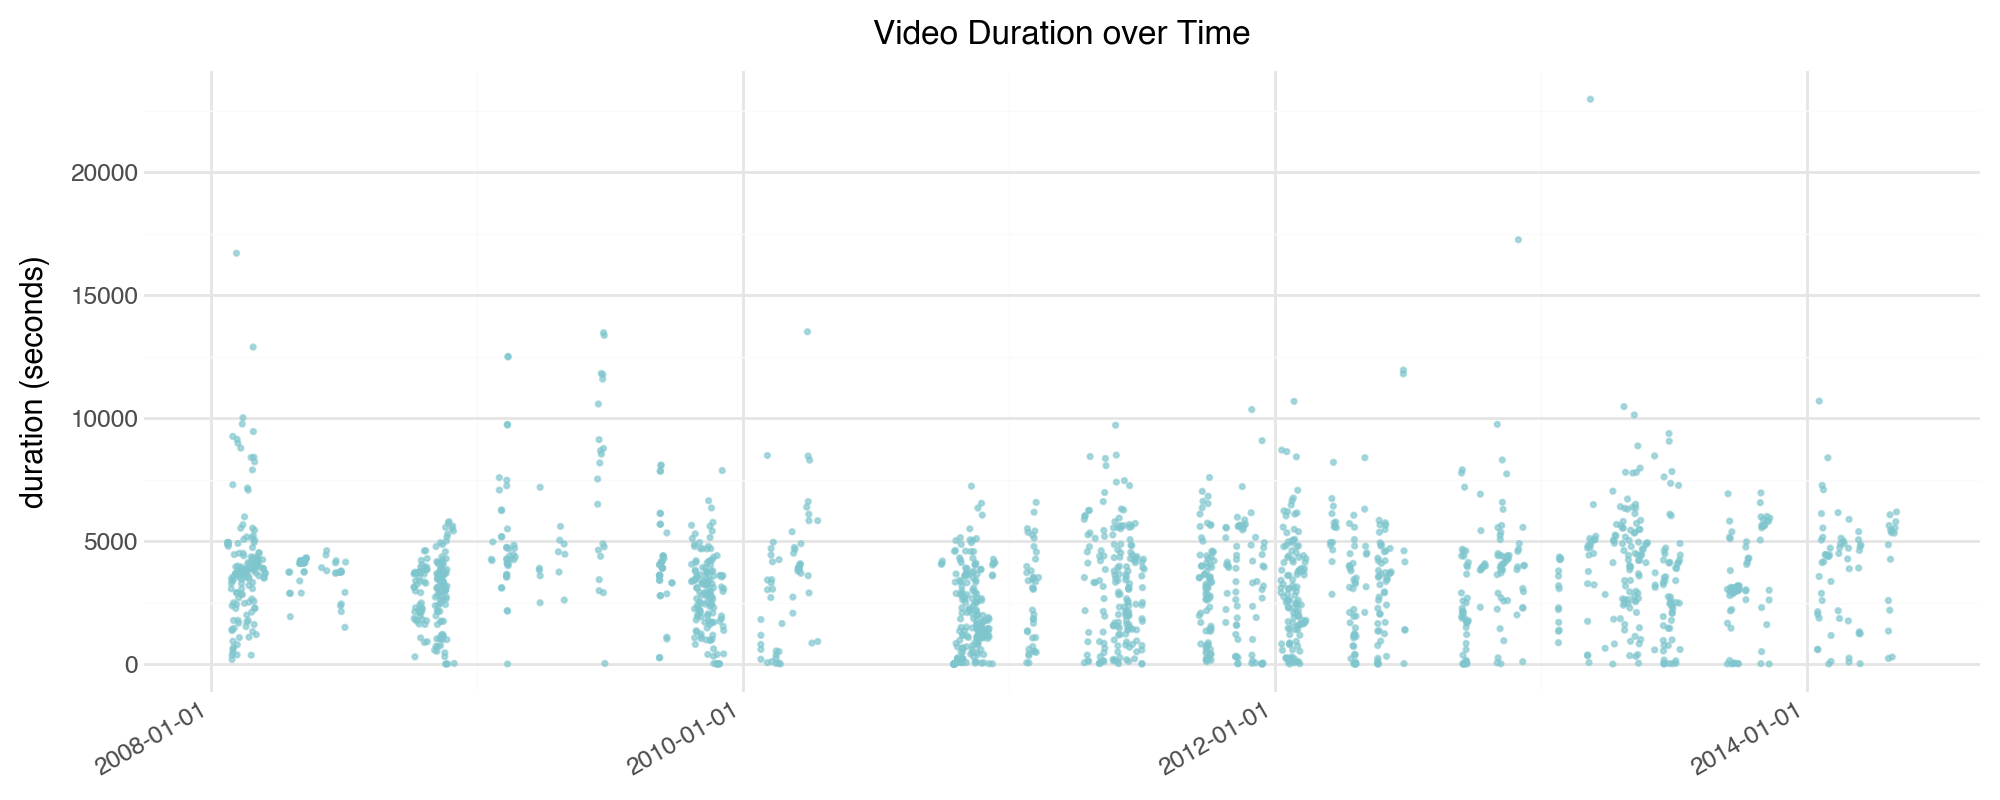

In [29]:
gg = (
    ggplot(video_df, aes(x='happened_at', y='dur'))
    + geom_point(size=0.5, alpha=0.6, color=PASTEL_BLUE)
    + labs(title=L('Videodauer über Zeit', 'Video Duration over Time'),
           x='', y=L('Dauer (Sekunden)', 'duration (seconds)'))
    + theme(
        axis_text_x=element_text(rotation=30, hjust=1),
        figure_size=(10, 4)
    )
)

gg

In [30]:
# total video duration of Theatrical Arsenal II (piece 52)
mask = (events_df['event_type'] == 'video') & (events_df['piece_id'] == 52)
durs = pd.to_numeric(events_df.loc[mask, 'dur'], errors='coerce').dropna()
total_seconds = durs.sum()

print(f"Total duration of videos (seconds): {total_seconds}")
total_td = pd.to_timedelta(total_seconds, unit='s')

days = total_td.days
hours, rem = divmod(total_td.seconds, 3600)
minutes, seconds = divmod(rem, 60)

formatted = f"{days:02d}:{hours:02d}:{minutes:02d}:{seconds:02d}"
print(f"Total duration of videos (dd:hh:mm:ss): {formatted}")

Total duration of videos (seconds): 797016.0
Total duration of videos (dd:hh:mm:ss): 09:05:23:36


In [31]:
median_dur = video_df['dur'].median()
q1, q3 = video_df['dur'].quantile([0.25, 0.75])
print(f"median video duration: {median_dur/60:.1f} min (IQR {q1/60:.1f}-{q3/60:.1f} min)")

median video duration: 56.6 min (IQR 28.5-74.2 min)


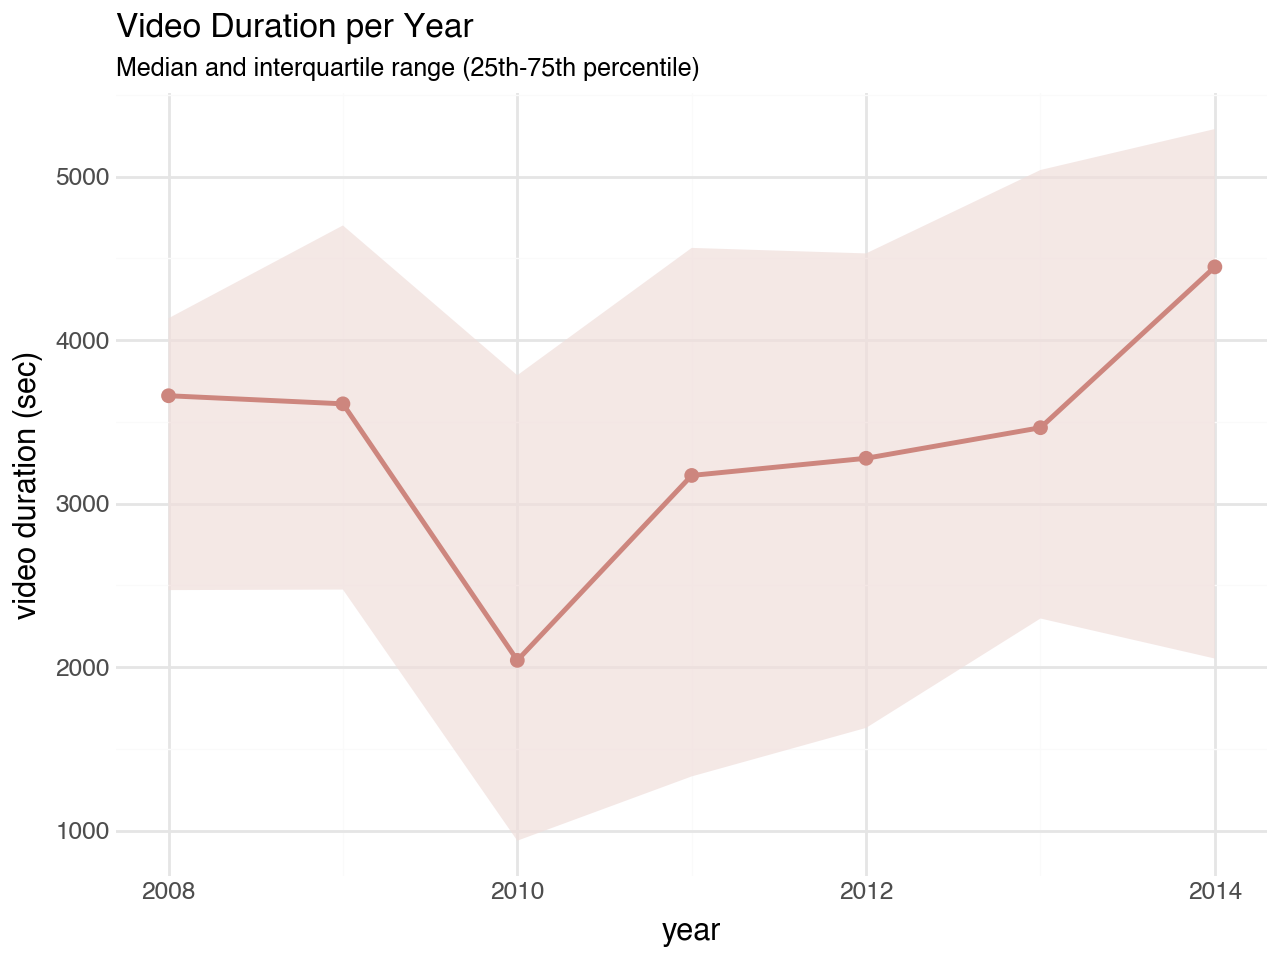

In [32]:
video_df['year'] = video_df['happened_at'].dt.year

yearly_stats = (
    video_df.groupby('year')['dur']
    .agg(median='median', q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75))
    .reset_index()
)
gg = (
    ggplot(yearly_stats, aes(x='year'))
    + geom_ribbon(aes(ymin='q25', ymax='q75'), fill=RIBBON_WARM, alpha=0.7)
    + geom_line(aes(y='median'), color=PASTEL_RED, size=1)
    + geom_point(aes(y='median'), color=PASTEL_RED, size=2)
    + labs(
        title=L('Videodauer pro Jahr', 'Video Duration per Year'),
        subtitle=L('Median und Interquartilsabstand (25.–75. Perzentil)',
                   'Median and interquartile range (25th-75th percentile)'),
        x=L('Jahr', 'year'),
        y=L('Videodauer (Sek.)', 'video duration (sec)')
    )
)
gg

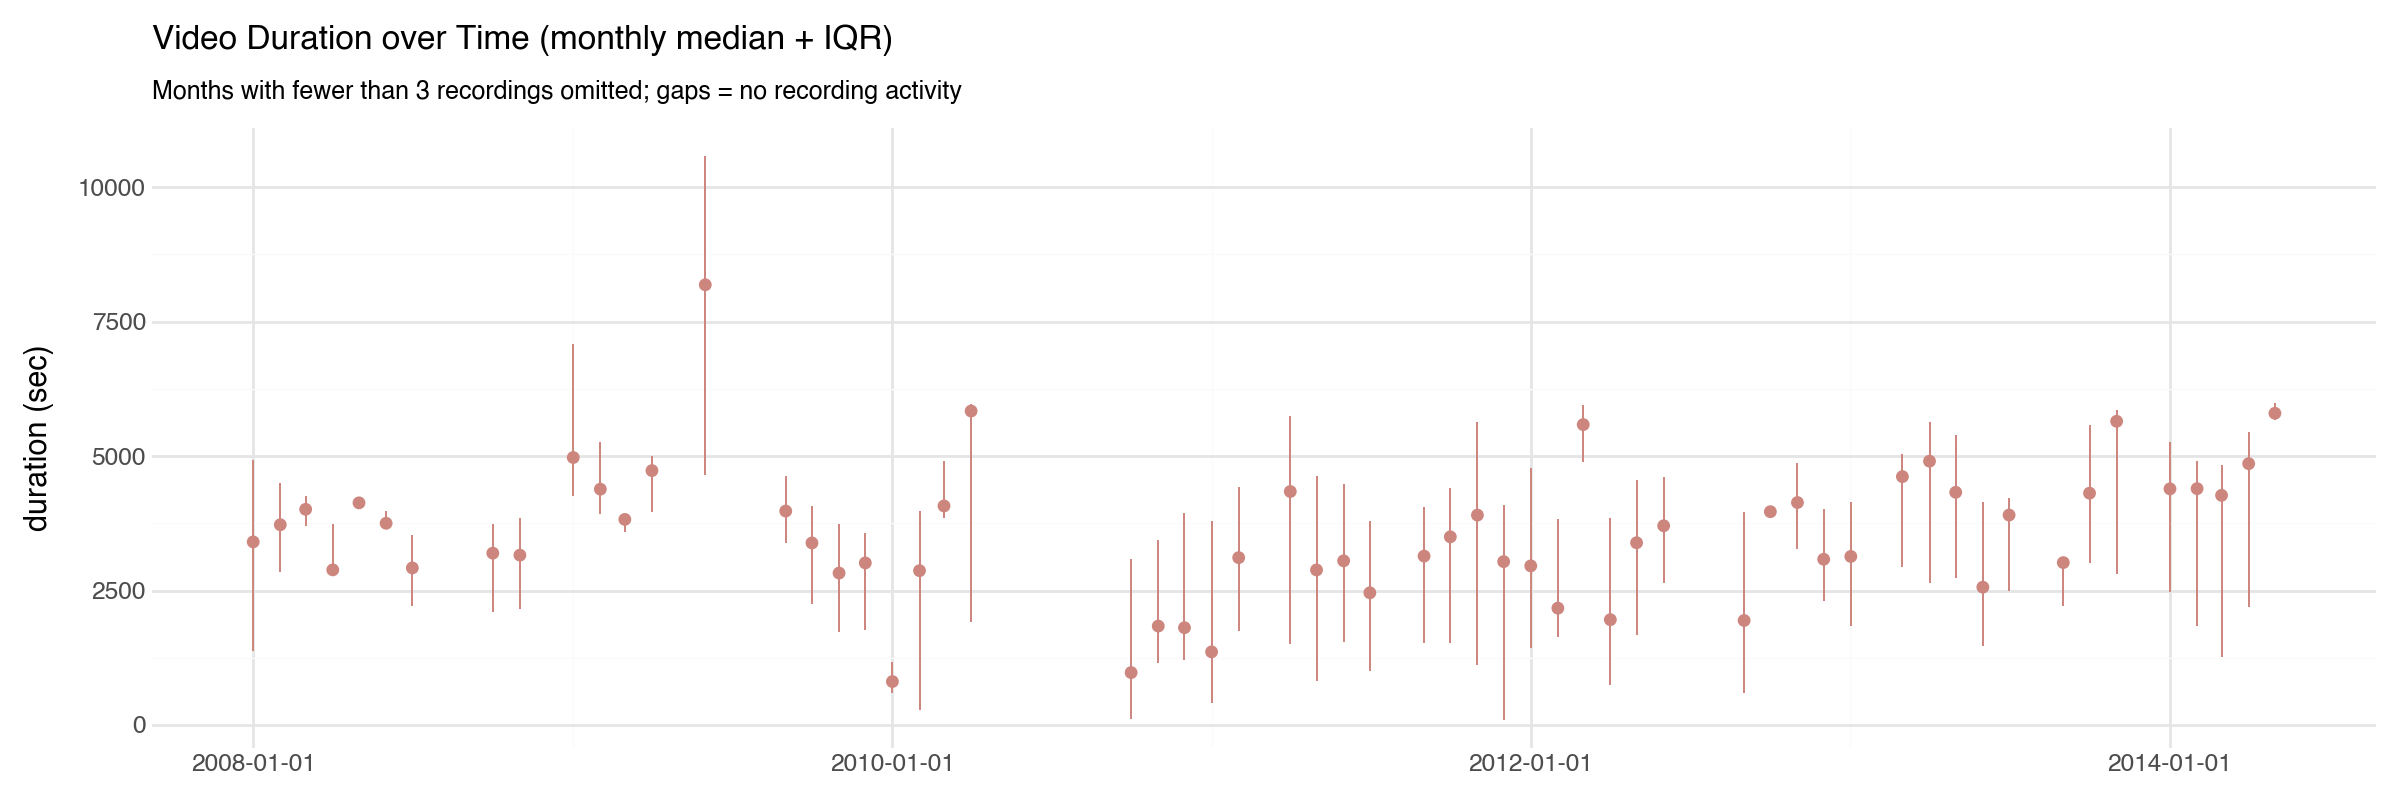

In [33]:
video_df['month'] = video_df['happened_at'].dt.to_period('M').dt.to_timestamp()
monthly = (
    video_df.groupby('month')['dur']
    .agg(median='median', q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75),
         n='size')
    .reset_index()
)
monthly = monthly[monthly['n'] >= 3]

gg = (
    ggplot(monthly, aes(x='month', y='median'))
    + geom_pointrange(aes(ymin='q25', ymax='q75'), color=PASTEL_RED, size=0.4)
    + labs(
        title=L('Videodauer über Zeit (Monatsmedian + IQR)',
                'Video Duration over Time (monthly median + IQR)'),
        subtitle=L('Monate mit weniger als 3 Aufnahmen ausgelassen; Lücken = keine Aufnahmen',
                   'Months with fewer than 3 recordings omitted; gaps = no recording activity'),
        x='',
        y=L('Dauer (Sek.)', 'duration (sec)')
    )
    + theme(figure_size=(12, 4))
)
gg

## Annotation text length

Character length of the annotation texts over time, again with median and IQR because of the skew. Shifts here can point to changes in documentation practice.


In [34]:
text_df = events_df[events_df['description'].notna()][['happened_at', 'description', 'created_by']].copy()

text_df['text_length'] = text_df['description'].apply(len)
text_df['happened_at'] = pd.to_datetime(text_df['happened_at'])
text_df['year'] = text_df['happened_at'].dt.year
text_df = text_df[text_df['year'] >= 2008]
text_df = text_df[text_df['text_length'].notna() & (text_df['text_length'] > 0)]

print(f"n = {len(text_df)} annotations with description text")
print(f"median length: {text_df['text_length'].median():.0f} characters "
      f"(IQR {text_df['text_length'].quantile(0.25):.0f}-{text_df['text_length'].quantile(0.75):.0f})")
print(f"mean: {text_df['text_length'].mean():.1f}, sd: {text_df['text_length'].std():.1f} "
      "(reported for completeness - distribution is right-skewed)")

n = 4439 annotations with description text


median length: 117 characters (IQR 54-242)
mean: 233.0, sd: 492.1 (reported for completeness - distribution is right-skewed)


In [35]:
yearly_stats = (
    text_df.groupby('year')['text_length']
    .agg(median='median', q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75))
    .reset_index()
)
yearly_stats

,year,median,q25,q75
0,2008.0,97.0,49.00,197.0
1,2009.0,207.5,109.00,407.5
2,2010.0,120.0,49.75,258.0
3,2011.0,96.0,48.00,208.0
4,2012.0,72.0,38.00,131.0
5,2013.0,93.0,46.00,191.0


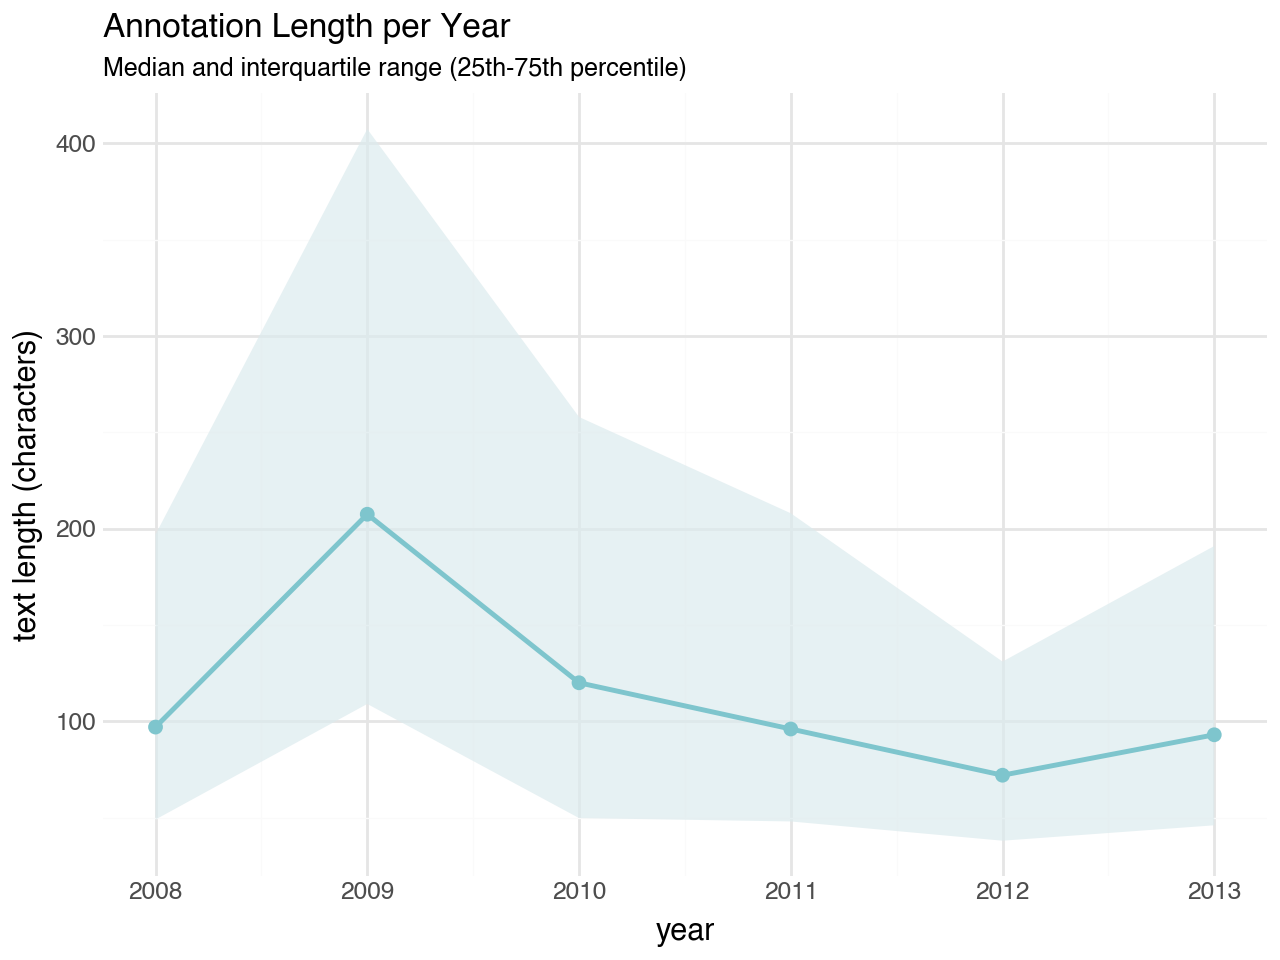

In [36]:
gg = (
    ggplot(yearly_stats, aes(x='year'))
    + geom_ribbon(aes(ymin='q25', ymax='q75'), fill=RIBBON_COOL, alpha=0.7)
    + geom_line(aes(y='median'), color=PASTEL_BLUE, size=1)
    + geom_point(aes(y='median'), color=PASTEL_BLUE, size=2)
    + labs(
        title=L('Annotationslänge pro Jahr', 'Annotation Length per Year'),
        subtitle=L('Median und Interquartilsabstand (25.–75. Perzentil)',
                   'Median and interquartile range (25th-75th percentile)'),
        x=L('Jahr', 'year'),
        y=L('Textlänge (Zeichen)', 'text length (characters)')
    )
)
gg

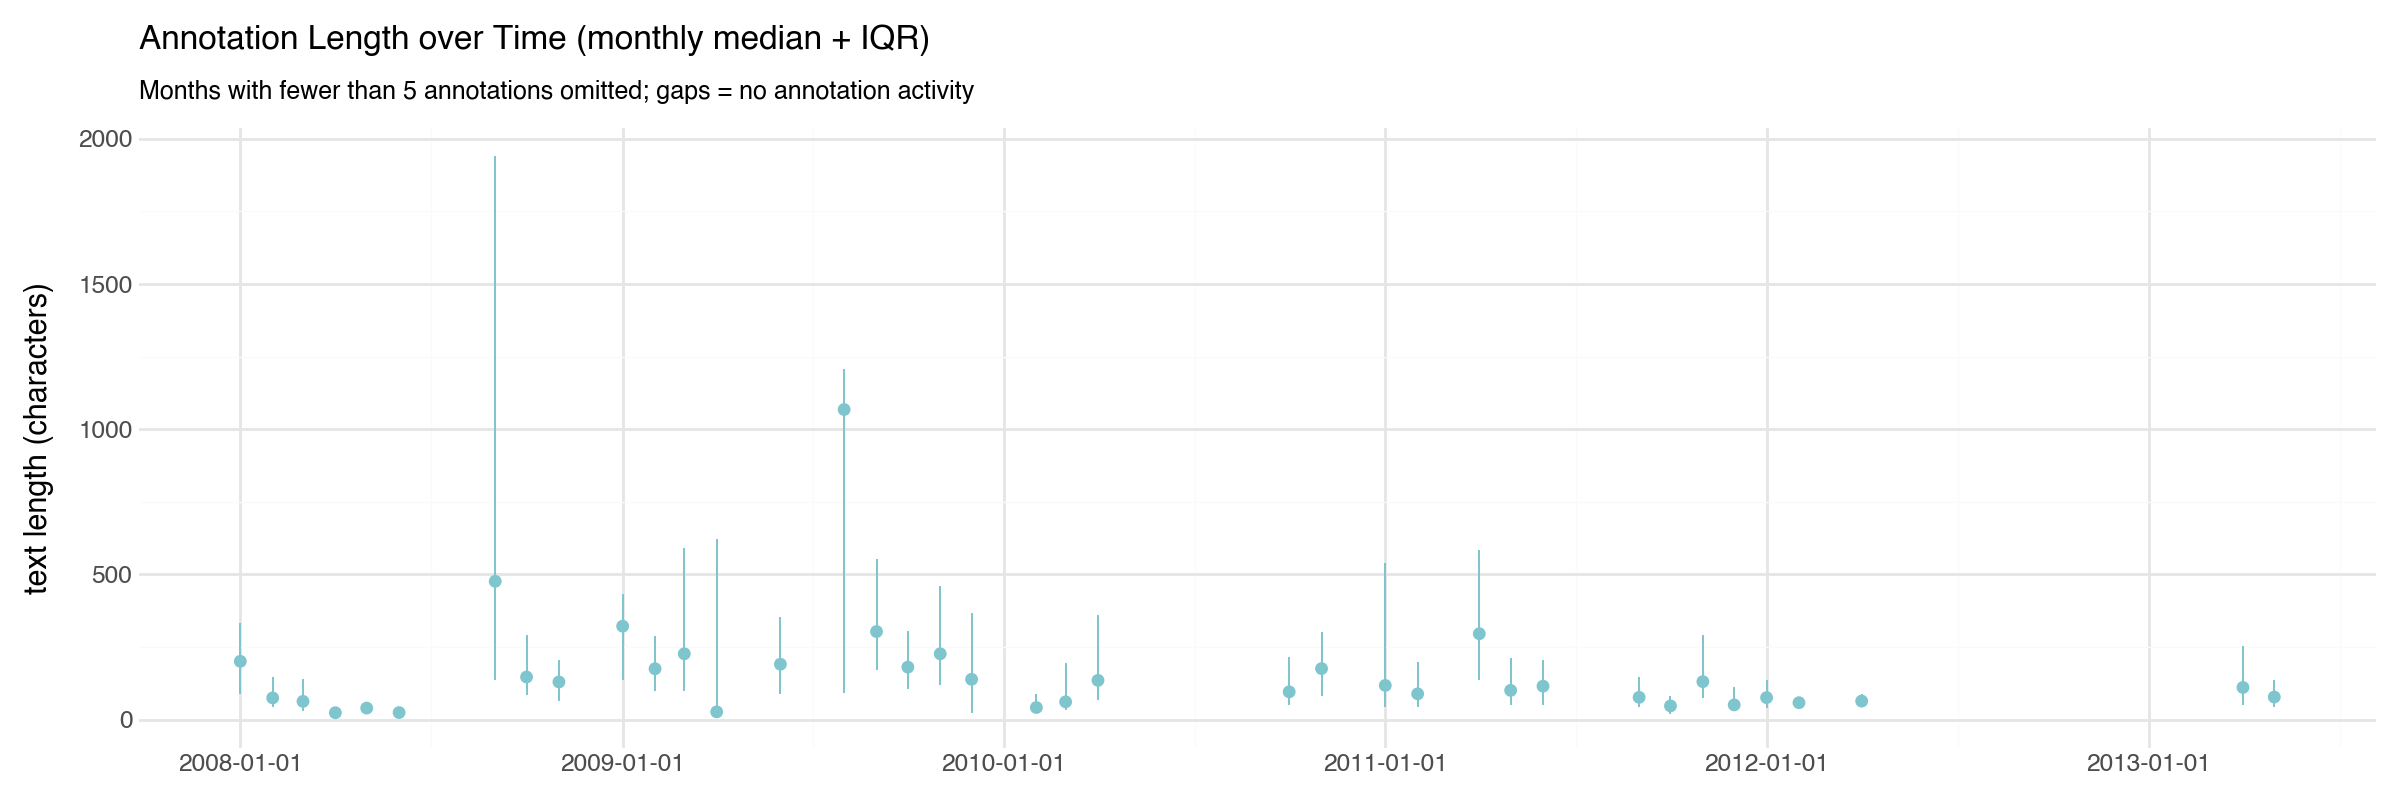

In [37]:
text_df['month'] = text_df['happened_at'].dt.to_period('M').dt.to_timestamp()
monthly_len = (
    text_df.groupby('month')['text_length']
    .agg(median='median', q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75),
         n='size')
    .reset_index()
)
monthly_len = monthly_len[monthly_len['n'] >= 5]

gg = (
    ggplot(monthly_len, aes(x='month', y='median'))
    + geom_pointrange(aes(ymin='q25', ymax='q75'), color=PASTEL_BLUE, size=0.4)
    + scale_y_continuous(limits=[0, None])
    + labs(
        title=L('Annotationslänge über Zeit (Monatsmedian + IQR)',
                'Annotation Length over Time (monthly median + IQR)'),
        subtitle=L('Monate mit weniger als 5 Annotationen ausgelassen; Lücken = keine Annotationen',
                   'Months with fewer than 5 annotations omitted; gaps = no annotation activity'),
        x='',
        y=L('Textlänge (Zeichen)', 'text length (characters)')
    )
    + theme(figure_size=(12, 4))
)
gg

In [38]:
events_df['has_text'] = events_df['description'].notna()
text_count_df = events_df[events_df['has_text']].copy()

text_count_df['happened_at'] = pd.to_datetime(text_count_df['happened_at'])
text_count_df['year'] = text_count_df['happened_at'].dt.year

text_count_df = text_count_df[text_count_df['year'] >= 2008]

In [39]:
yearly_counts = (
    text_count_df.groupby('year')
    .size()
    .reset_index(name='text_count')
)

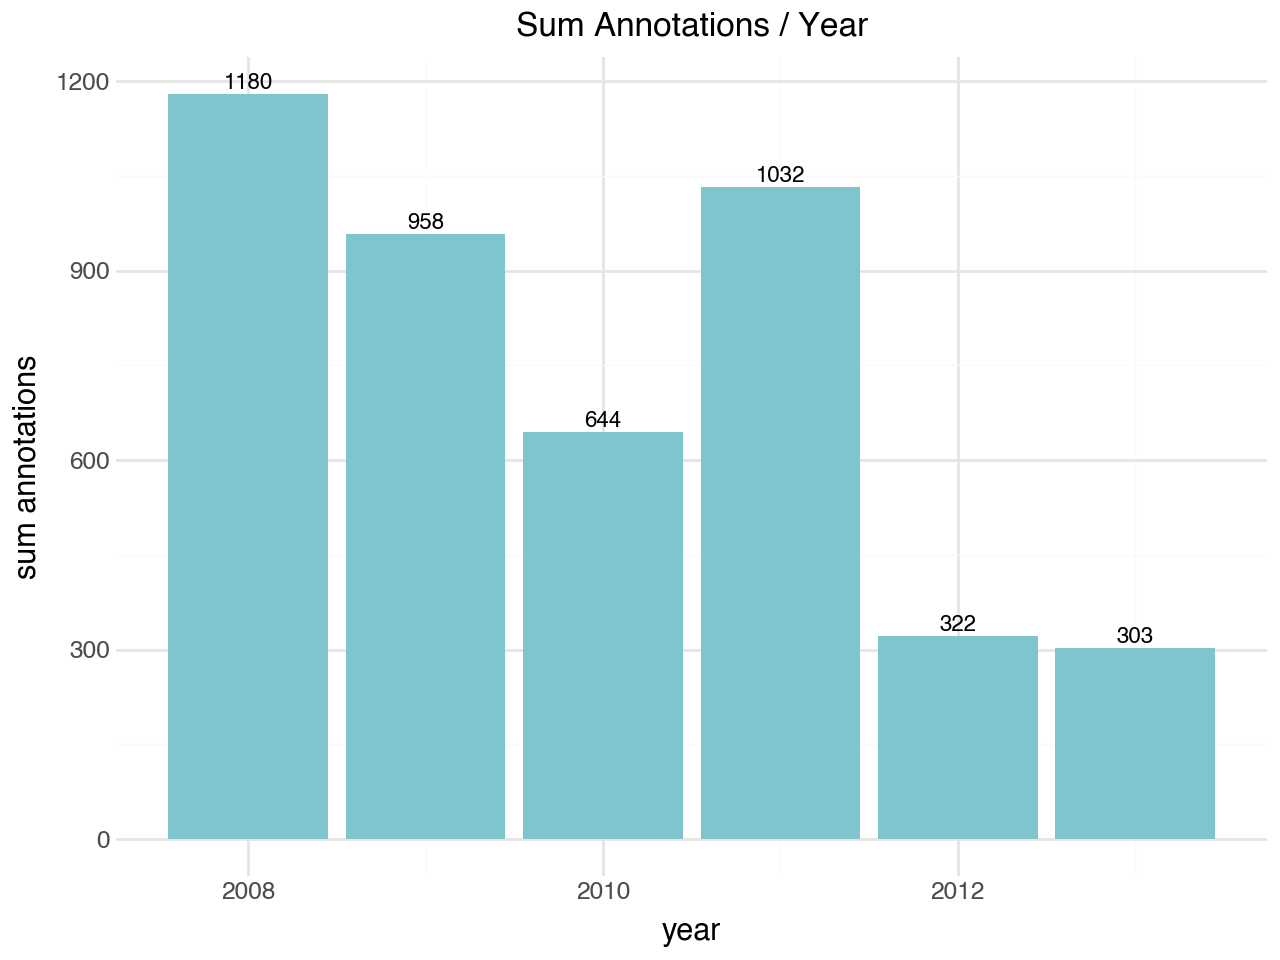

In [40]:
gg_year = (
    ggplot(yearly_counts, aes(x='year', y='text_count'))
    + geom_col(fill=PASTEL_BLUE)
    + geom_text(aes(label='text_count'), va='bottom', size=8, format_string='{:.0f}')
    + labs(
        title=L('Annotationen pro Jahr', 'Sum Annotations / Year'),
        x=L('Jahr', 'year'),
        y=L('Summe Annotationen', 'sum annotations')
    )
)
gg_year

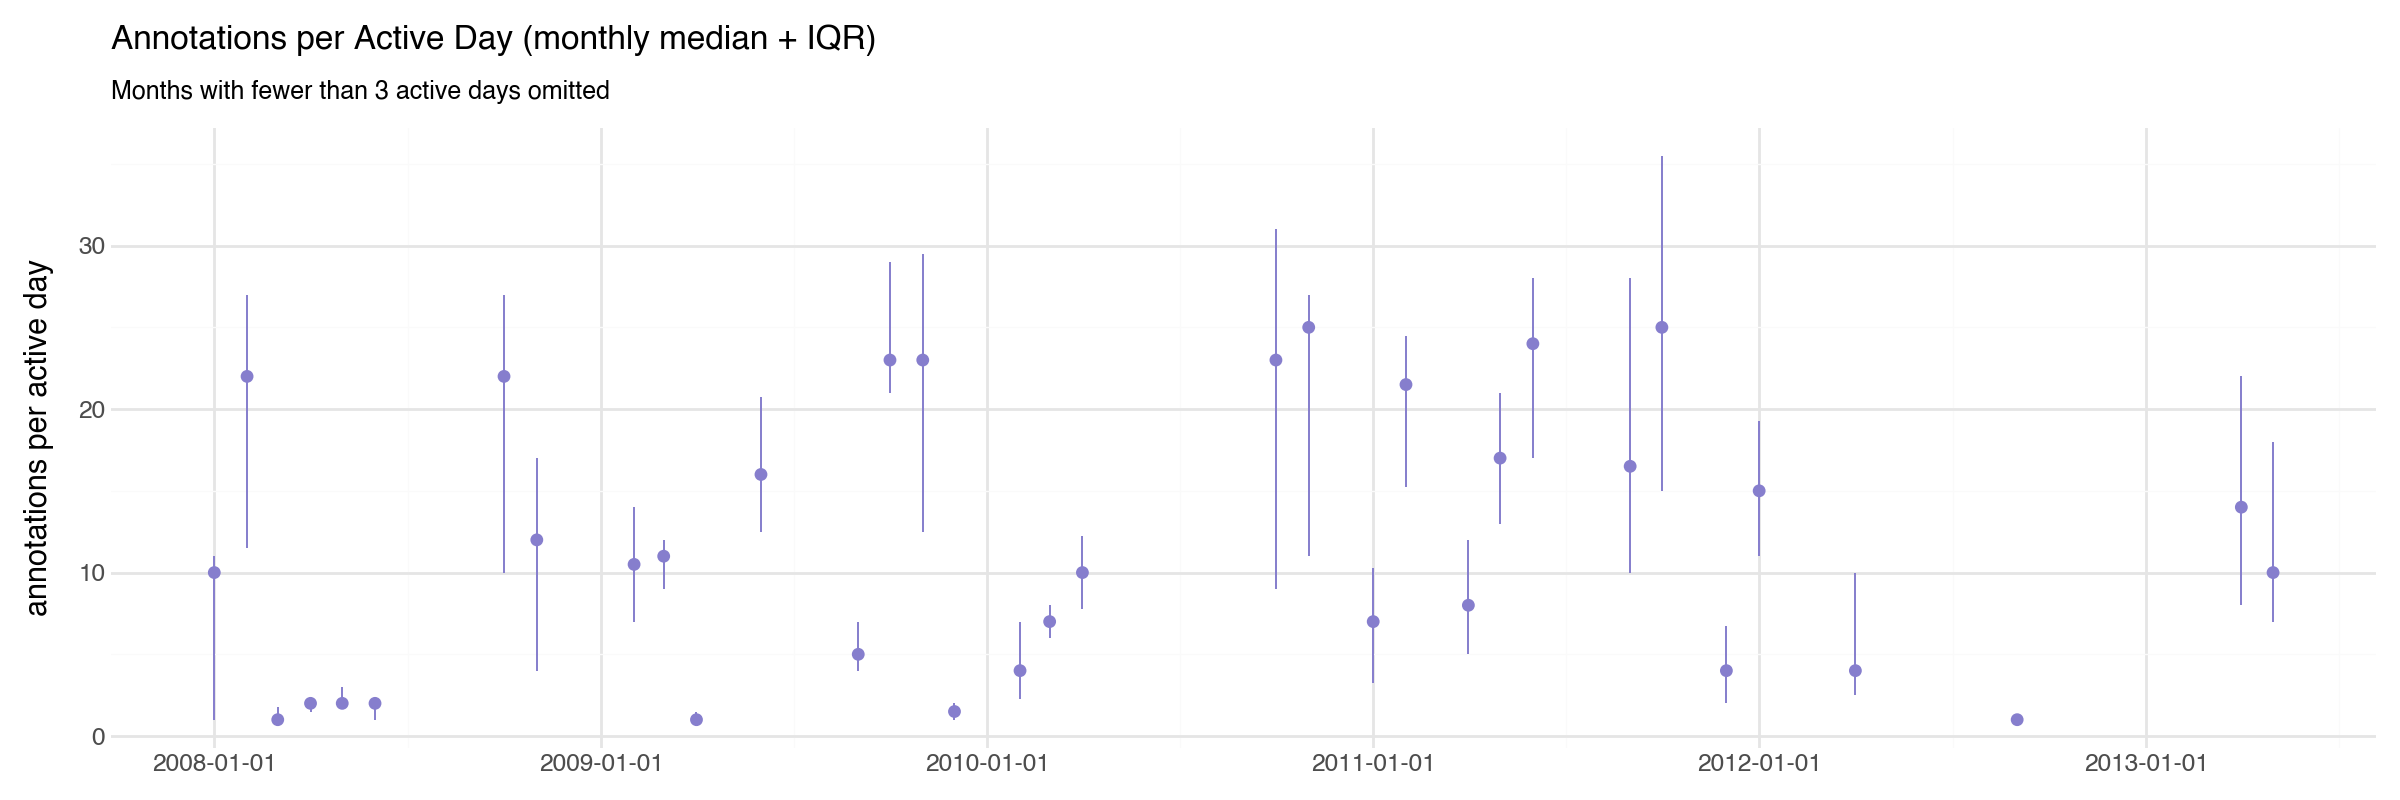

In [41]:
daily_counts = (
    text_count_df.groupby(text_count_df['happened_at'].dt.date)
    .size()
    .reset_index(name='text_count')
    .rename(columns={'happened_at': 'date'})
)
daily_counts['date'] = pd.to_datetime(daily_counts['date'])
daily_counts['month'] = daily_counts['date'].dt.to_period('M').dt.to_timestamp()

monthly_counts = (
    daily_counts.groupby('month')['text_count']
    .agg(median='median', q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75),
         n='size')
    .reset_index()
)
monthly_counts = monthly_counts[monthly_counts['n'] >= 3]

gg_day = (
    ggplot(monthly_counts, aes(x='month', y='median'))
    + geom_pointrange(aes(ymin='q25', ymax='q75'), color=PASTEL_VIOLET, size=0.4)
    + labs(
        title=L('Annotationen pro aktivem Tag (Monatsmedian + IQR)',
                'Annotations per Active Day (monthly median + IQR)'),
        subtitle=L('Monate mit weniger als 3 aktiven Tagen ausgelassen',
                   'Months with fewer than 3 active days omitted'),
        x='',
        y=L('Annotationen pro aktivem Tag', 'annotations per active day')
    )
    + theme(figure_size=(12, 4))
)
gg_day